<div align="center">

# PlanificaIA
## Sistema multi-agente para la planificación de estudio personalizada

**Semana 9 · Hackathon 7 — Implementación de un sistema multi-agente**

| | |
|---|---|
| **Equipo** | NAN |
| **Integrantes** | Integrante 1 · Integrante 2 · Integrante 3 · Integrante 4 · Integrante 5 |
| **Caso seleccionado** | Caso 1 — Planificador de estudio personalizado |
| **Framework** | CrewAI (orquestación de agentes) + Ollama (LLM local) · compatible con Groq |
| **Fecha de entrega** | 12 de octubre de 2026 |

</div>

---

### Contenido
1. [Introducción del caso](#6.2-Introducción-del-caso)
2. [Diseño de agentes](#6.3-Diseño-de-agentes)
3. [Diseño del flujo de orquestación](#6.4-Diseño-del-flujo-de-orquestación)
4. [Implementación](#6.5-Implementación-con-CrewAI-+-Ollama-/-Groq)
5. [Resultados intermedios](#6.6-Resultados-intermedios)
6. [Decisión final](#6.7-Decisión-final)
7. [Evaluación crítica](#6.8-Evaluación-crítica)
8. [Conclusiones](#Conclusiones)

## 6.2 Introducción del caso

**¿Cuál es el problema?**
Un estudiante universitario lleva 5 cursos con distinta dificultad, créditos y fechas de evaluación, y tiene un tiempo libre fragmentado por clases, un trabajo de medio tiempo y traslados. Cada semana debe decidir **cuántas horas dedicar a cada curso, en qué día y en qué franja**. Hoy esa decisión se toma "a ojo": se estudia lo más urgente o lo que más gusta, y los cursos críticos quedan relegados hasta la víspera del examen.

**¿Por qué es importante?**
- La mala distribución del tiempo es una de las principales causas de bajo rendimiento y de desaprobación en los primeros ciclos.
- Concentrar el estudio en la noche anterior aumenta el estrés y reduce la retención (frente a la práctica espaciada).
- Un plan que no respeta la disponibilidad real **no se cumple**: el problema no es solo priorizar, sino priorizar dentro de restricciones.

**¿Qué decisión se busca apoyar?**
Elegir **un plan semanal de estudio** (sesiones con día, hora, curso y actividad) entre varias alternativas, de modo que:
1. priorice los cursos en riesgo y las evaluaciones cercanas,
2. respete las restricciones duras (bloques libres, máximo de horas por día, fechas límite), y
3. sea sostenible (balance de carga, descanso y preferencias personales).

**¿Quién usará este sistema?**
- **Usuario principal:** el estudiante, que recibe un plan semanal justificado.
- **Usuarios secundarios:** tutores o consejeros académicos, que pueden usarlo para preparar sesiones de acompañamiento a alumnos en riesgo.

**¿Qué impacto tendría?**
- Menos tiempo decidiendo *qué estudiar* y más tiempo estudiando.
- Detección temprana de cursos en riesgo (p. ej., nota actual 11 en un curso de dificultad 5).
- Planes **verificables**: cada propuesta pasa por un auditor que comprueba con código que el plan es realizable.

**Criterios de decisión** (definidos por el equipo y usados por el agente evaluador):

| Criterio | Peso | Pregunta que responde |
|---|---|---|
| Prioridad académica | 30 % | ¿Dedica suficientes horas, a tiempo, a los cursos críticos y evaluaciones cercanas? |
| Factibilidad | 25 % | ¿Cumple las restricciones duras (bloques, horas/día, fechas límite)? |
| Balance de carga | 20 % | ¿Distribuye el esfuerzo sin picos excesivos? |
| Bienestar | 15 % | ¿Evita sobrecarga y sesiones demasiado largas? |
| Preferencias | 10 % | ¿Respeta preferencias del estudiante (p. ej., cursos difíciles en la mañana)? |

## 6.3 Diseño de agentes

El sistema tiene **5 agentes**: los 4 recomendados en el enunciado más un **Auditor de factibilidad** que propusimos como agente adicional.

| # | Agente | Rol | Objetivo | Qué recibe | Qué produce |
|---|---|---|---|---|---|
| 1 | **Analista del estudiante** | Experto en análisis académico | Entender contexto, restricciones y prioridades | Perfil del estudiante (cursos, notas, evaluaciones, disponibilidad, restricciones) | Resumen estructurado: prioridades, riesgos, horas disponibles, datos faltantes |
| 2 | **Planificador** | Diseñador de planes de estudio | Generar alternativas de planificación | Análisis + perfil original (+ retroalimentación del auditor si hay re-planificación) | **3 planes semanales** en JSON validado (Pydantic) |
| 3 | **Auditor de factibilidad** ⭐ *(adicional)* | Verificador de restricciones | Comprobar que cada plan sea realizable y decir cómo corregirlo | Planes + **reporte de verificación calculado en Python** | Veredicto por plan (APTO / CON OBSERVACIONES / NO APTO) + instrucciones de corrección |
| 4 | **Evaluador** | Evaluador de carga académica | Comparar planes con criterios ponderados | Análisis + planes + métricas + auditoría | Puntajes 1–5 por criterio, ventajas y desventajas (JSON) |
| 5 | **Decisor** | Asesor académico | Recomendar el mejor plan | Todo lo anterior + puntaje ponderado | Decisión final justificada, riesgos, puntos de revisión humana y horario final |

### ¿Por qué un agente adicional (Auditor de factibilidad)?

En las primeras pruebas observamos que el planificador (un LLM) **propone sesiones fuera de los bloques libres, suma mal las horas o programa estudio después de la evaluación**. Los LLM no son confiables haciendo aritmética de horarios. Si esos errores llegan al evaluador, este puede premiar un plan que en la práctica es imposible de cumplir.

El Auditor resuelve esto con un diseño **híbrido**:
1. **Verificación determinista (Python):** calcula horas por día y por curso, detecta solapamientos, sesiones fuera de bloque, violación de fechas límite y cobertura de cursos críticos. Esto es exacto y reproducible.
2. **Interpretación (LLM):** traduce el reporte en un veredicto y en **instrucciones concretas de corrección** ("mover la sesión de Ética del miércoles al lunes 20:00–21:00").

Además, el auditor habilita un **bucle de corrección**: si algún plan tiene violaciones duras, su retroalimentación vuelve al planificador (máximo 2 rondas). Así, el evaluador y el decisor trabajan sobre planes que ya fueron verificados, y las métricas exactas sirven como evidencia objetiva para puntuar.

### Separación de responsabilidades
- Ningún agente hace el trabajo de otro: el analista **no propone horarios**, el planificador **no evalúa**, el evaluador **no calcula el puntaje final** (lo hace Python con los pesos definidos) y el decisor **no inventa planes nuevos**.
- Cada agente usa una **temperatura** acorde a su tarea: baja (0.1–0.2) para analizar, auditar, evaluar y decidir; más alta (0.5) para que el planificador genere alternativas diversas.

## 6.4 Diseño del flujo de orquestación

**Tipo de flujo:** **secuencial con un bucle condicional de corrección** (iterativo acotado).

| Paso | Agente | Entrada | Salida que pasa al siguiente |
|---|---|---|---|
| 1 | Analista | Perfil del estudiante (JSON) | `analisis` (Markdown) |
| 2 | Planificador | `analisis` + perfil | `planes` (JSON Pydantic, 3 planes) |
| 3a | Verificador Python | `planes` + perfil | `reporte` (métricas y violaciones duras) |
| 3b | Auditor | `planes` + `reporte` | `informe_auditor` (veredictos + correcciones) |
| ↺ | *Condición* | ¿algún plan con violaciones duras **y** rondas < 2? | Sí → vuelve al paso 2 con `informe_auditor` como retroalimentación |
| 4 | Evaluador | `analisis` + `planes` + `reporte` + `informe_auditor` | `evaluacion` (puntajes 1–5 por criterio) |
| 4b | Python | `evaluacion` + pesos | `puntajes` ponderados y ranking |
| 5 | **Decisor (integrador)** | Todo lo anterior | **Decisión final** + horario |
| 6 | Persona | Decisión | Validación humana antes de aplicar |

- **Quién integra la respuesta final:** el **Decisor** (Asesor académico) es el único que ve todas las salidas y produce la recomendación.
- **Por qué la condición del bucle la decide Python y no un LLM:** así el bucle es predecible (no depende de que un modelo "opine" que el plan está bien) y está acotado a 2 rondas para controlar costo y tiempo.
- **Implementación:** cada paso se ejecuta como una `Crew` de CrewAI con un agente y una tarea; un **orquestador en Python** encadena las salidas (vía `inputs` interpolados en los prompts) y evalúa la condición del bucle.

```mermaid
flowchart TD
    D[/"Perfil del estudiante"/] --> A1["1 · Analista del estudiante"]
    A1 -- análisis --> A2["2 · Planificador"]
    A2 -- "3 planes (JSON)" --> V["3a · Verificador Python"]
    V -- reporte --> A3["3b · Auditor de factibilidad ⭐"]
    A3 --> C{"¿Violaciones duras<br/>y ronda < 2?"}
    C -- "Sí: retroalimentación" --> A2
    C -- No --> A4["4 · Evaluador de carga"]
    A4 -- "puntajes 1–5" --> P["4b · Puntaje ponderado (Python)"]
    P --> A5["5 · Decisor / Asesor académico"]
    A5 --> F[/"Plan recomendado + riesgos"/]
    F --> H(["Revisión humana"])
```

El mismo diagrama se genera como imagen (`diagrama_flujo.png`) en la siguiente celda, para que se vea en cualquier visor y pueda usarse en la presentación.

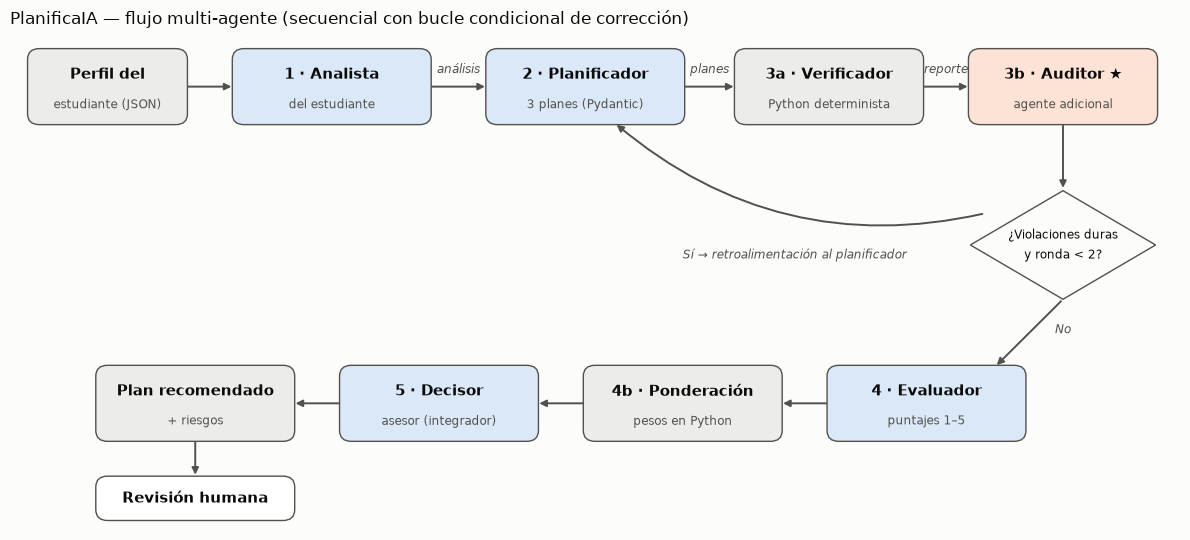

In [1]:
# Diagrama del flujo multi-agente (se guarda como PNG para la presentación)
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon

TINTA, TINTA_2, FONDO = "#0b0b0b", "#52514e", "#fcfcfb"
COLOR_AGENTE, COLOR_PY, COLOR_EXTRA = "#dbe8f8", "#ececea", "#fde3d6"

fig, ax = plt.subplots(figsize=(12, 5.5), facecolor=FONDO)
ax.set_xlim(0, 12); ax.set_ylim(0, 5.5); ax.axis("off")

def caja(x, y, w, h, texto, color, sub=None):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc=color, ec=TINTA_2, lw=1))
    ax.text(x, y + (0.13 if sub else 0), texto, ha="center", va="center", fontsize=10.5, color=TINTA, weight="bold")
    if sub:
        ax.text(x, y - 0.2, sub, ha="center", va="center", fontsize=8.5, color=TINTA_2)

def flecha(x1, y1, x2, y2, texto=None, curva=0.0, dx=0, dy=0.15):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color=TINTA_2, lw=1.4, connectionstyle=f"arc3,rad={curva}"))
    if texto:
        ax.text((x1 + x2)/2 + dx, (y1 + y2)/2 + dy, texto, ha="center", fontsize=8.5, color=TINTA_2, style="italic")

# Fila superior: datos -> analista -> planificador -> verificador -> auditor
caja(1.0, 4.9, 1.6, 0.8, "Perfil del", COLOR_PY, "estudiante (JSON)")
caja(3.3, 4.9, 2.0, 0.8, "1 · Analista", COLOR_AGENTE, "del estudiante")
caja(5.9, 4.9, 2.0, 0.8, "2 · Planificador", COLOR_AGENTE, "3 planes (Pydantic)")
caja(8.4, 4.9, 1.9, 0.8, "3a · Verificador", COLOR_PY, "Python determinista")
caja(10.8, 4.9, 1.9, 0.8, "3b · Auditor ★", COLOR_EXTRA, "agente adicional")
flecha(1.8, 4.9, 2.3, 4.9)
flecha(4.3, 4.9, 4.9, 4.9, "análisis")
flecha(6.9, 4.9, 7.45, 4.9, "planes")
flecha(9.35, 4.9, 9.85, 4.9, "reporte")

# Decisión condicional
rombo = Polygon([[10.8, 3.75], [11.75, 3.15], [10.8, 2.55], [9.85, 3.15]], closed=True, fc=FONDO, ec=TINTA_2, lw=1)
ax.add_patch(rombo)
ax.text(10.8, 3.22, "¿Violaciones duras", ha="center", fontsize=8.5, color=TINTA)
ax.text(10.8, 3.0, "y ronda < 2?", ha="center", fontsize=8.5, color=TINTA)
flecha(10.8, 4.5, 10.8, 3.75)
flecha(10.0, 3.5, 6.2, 4.5, curva=-0.25)
ax.text(6.9, 3.0, "Sí → retroalimentación al planificador", fontsize=8.5, color=TINTA_2, style="italic")

# Fila inferior: evaluador -> puntaje -> decisor -> salida -> humano
caja(9.4, 1.4, 2.0, 0.8, "4 · Evaluador", COLOR_AGENTE, "puntajes 1–5")
caja(6.9, 1.4, 2.0, 0.8, "4b · Ponderación", COLOR_PY, "pesos en Python")
caja(4.4, 1.4, 2.0, 0.8, "5 · Decisor", COLOR_AGENTE, "asesor (integrador)")
caja(1.9, 1.4, 2.0, 0.8, "Plan recomendado", COLOR_PY, "+ riesgos")
flecha(10.8, 2.55, 10.1, 1.8, "No", dx=0.35, dy=0.0)
flecha(8.4, 1.4, 7.9, 1.4)
flecha(5.9, 1.4, 5.4, 1.4)
flecha(3.4, 1.4, 2.9, 1.4)
caja(1.9, 0.35, 2.0, 0.45, "Revisión humana", "#ffffff")
flecha(1.9, 1.0, 1.9, 0.58)

ax.set_title("PlanificaIA — flujo multi-agente (secuencial con bucle condicional de corrección)",
             fontsize=12.5, color=TINTA, loc="left", pad=6)
plt.tight_layout()
plt.savefig("diagrama_flujo.png", dpi=180, facecolor=FONDO, bbox_inches="tight")
plt.show()

## 6.5 Implementación con CrewAI + Ollama / Groq

### 6.5.1 Configuración del entorno

**Framework de agentes: CrewAI.** Cada agente se define con `role`, `goal` y `backstory` (su *system prompt*), y cada tarea con `description` y `expected_output`. CrewAI se encarga de construir los mensajes, llamar al LLM y validar salidas estructuradas con Pydantic.

**Motor de lenguaje:** el notebook funciona con dos proveedores, seleccionables con una variable:

| Proveedor | Modelo | Cuándo usarlo |
|---|---|---|
| `ollama` *(por defecto)* | `qwen2.5:7b` con contexto de 16 K tokens | Ejecución **local**, sin costo ni API key; es el entorno que usamos en clase |
| `groq` | `llama-3.3-70b-versatile` | Ejecución en la nube, mucho más rápida y con un modelo más grande; requiere `GROQ_API_KEY` |

**¿Por qué `qwen2.5:7b`?** Probamos modelos más grandes disponibles localmente (`gpt-oss:20b`, `qwen2.5-coder:14b`) pero generaban menos de 3 tokens/s en nuestra laptop (24 GB de RAM compartida), lo que hacía inviable un flujo de 5+ llamadas. `qwen2.5:7b` es rápido, sigue bien instrucciones en español y genera JSON válido de forma consistente. Su desventaja (menor capacidad de razonamiento) es justamente la que compensa el **Auditor de factibilidad**.

**Importante — ventana de contexto:** Ollama usa por defecto un contexto corto (≈4 K tokens) y **trunca en silencio** los prompts largos. Como el decisor recibe análisis + planes + auditoría + evaluación, creamos una variante del modelo con `num_ctx = 16384` mediante un `Modelfile`.

```bash
# Instalación (una sola vez)
pip install -U crewai pandas matplotlib python-dotenv
ollama pull qwen2.5:7b
```

In [2]:
import os
# Desactivamos telemetría/trazas remotas de CrewAI: el sistema corre 100 % local
os.environ["CREWAI_TELEMETRY_OPT_OUT"] = "true"
os.environ["OTEL_SDK_DISABLED"] = "true"
os.environ["CREWAI_TRACING_ENABLED"] = "false"

import json, re, time, subprocess, unicodedata, warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from typing import Optional

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pydantic import BaseModel, Field, field_validator, ValidationError
from crewai import Agent, Task, Crew, Process, LLM
import crewai

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
try:
    from dotenv import load_dotenv
    load_dotenv()  # lee GROQ_API_KEY / PROVEEDOR_LLM desde un archivo .env si existe
except ImportError:
    pass

SALIDAS = Path("salidas"); SALIDAS.mkdir(exist_ok=True)
print("CrewAI", crewai.__version__)

CrewAI 1.15.27


In [3]:
# ---- Selección del proveedor y modelo -------------------------------------------
PROVEEDOR = os.getenv("PROVEEDOR_LLM", "ollama")      # "ollama" (local) | "groq" (nube)
OLLAMA_URL = os.getenv("OLLAMA_HOST", "http://localhost:11434")
MODELO_BASE_OLLAMA = "qwen2.5:7b"
MODELO_OLLAMA = "qwen2.5-planifica"                   # qwen2.5:7b + num_ctx 16384
MODELO_GROQ = "llama-3.3-70b-versatile"

if PROVEEDOR == "ollama":
    # Crea (una vez) la variante con contexto ampliado a partir de un Modelfile
    Path("Modelfile").write_text(f"FROM {MODELO_BASE_OLLAMA}\nPARAMETER num_ctx 16384\n")
    modelos = subprocess.run(["ollama", "list"], capture_output=True, text=True).stdout
    if MODELO_OLLAMA not in modelos:
        subprocess.run(["ollama", "create", MODELO_OLLAMA, "-f", "Modelfile"], check=True)
    print(subprocess.run(["ollama", "show", MODELO_OLLAMA], capture_output=True, text=True).stdout)


def crear_llm(temperatura: float) -> LLM:
    # Devuelve el LLM configurado. Cada agente recibe su propia instancia con su temperatura.
    if PROVEEDOR == "groq":
        # Groq expone una API compatible con OpenAI
        return LLM(model=MODELO_GROQ, custom_openai=True, base_url="https://api.groq.com/openai/v1",
                   api_key=os.environ["GROQ_API_KEY"], temperature=temperatura, max_tokens=4096)
    return LLM(model=f"ollama/{MODELO_OLLAMA}", base_url=OLLAMA_URL, temperature=temperatura)


# Prueba de humo: el modelo responde
t0 = time.time()
respuesta = crear_llm(0.0).call("Responde solo con la palabra: LISTO")
print(f"Proveedor: {PROVEEDOR} | Respuesta: {respuesta!r} | {time.time() - t0:.1f} s")

  Model
    architecture        qwen2     
    parameters          7.6B      
    context length      32768     
    embedding length    3584      
    quantization        Q4_K_M    

  Capabilities
    completion    
    tools         

  Parameters
    num_ctx    16384    

  System
    You are Qwen, created by Alibaba Cloud. You are a helpful assistant.    

  License
    Apache License               
    Version 2.0, January 2004    
    ...                          




Proveedor: ollama | Respuesta: 'LISTO' | 0.5 s


### 6.5.2 Datos del caso: perfil del estudiante

Usamos un perfil **ficticio pero realista** de una estudiante de 5.º ciclo para la semana del **lunes 12 al domingo 18 de octubre de 2026**. Los datos se separan en:
- **Cursos:** créditos, dificultad (1–5), nota actual (0–20), próxima evaluación, horas sugeridas de estudio y prioridad percibida.
- **Disponibilidad:** bloques libres por día (ya descontadas clases, trabajo de medio tiempo y traslados).
- **Restricciones duras** (si se violan, el plan no es realizable) y **preferencias** (deseables).
- **Fechas límite** en formato estructurado para que el verificador pueda comprobarlas.

In [4]:
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

ESTUDIANTE = {
    "nombre": "Andrea (perfil ficticio)",
    "carrera": "Ciencia de Datos e IA, 5.º ciclo",
    "semana": "Lunes 12 al domingo 18 de octubre de 2026 (semana 9)",
    "objetivo_personal": "Subir Machine Learning de 11 a 14 o más y entregar a tiempo el proyecto de Estadística",
    "cursos": [
        {"curso": "Machine Learning", "creditos": 4, "dificultad": 5, "nota_actual": 11,
         "proxima_evaluacion": "Examen parcial el lunes 19/10 (semana siguiente)",
         "fecha_limite": None, "horas_sugeridas": 7, "prioridad_estudiante": "alta"},
        {"curso": "Estadística Inferencial", "creditos": 4, "dificultad": 4, "nota_actual": 13,
         "proxima_evaluacion": "Entrega de proyecto el viernes 16/10 a las 23:59",
         "fecha_limite": {"dia": "Viernes", "hora": "23:59"}, "horas_sugeridas": 6, "prioridad_estudiante": "alta"},
        {"curso": "Bases de Datos II", "creditos": 3, "dificultad": 3, "nota_actual": 15,
         "proxima_evaluacion": "Laboratorio calificado el jueves 15/10 a las 10:00",
         "fecha_limite": {"dia": "Jueves", "hora": "10:00"}, "horas_sugeridas": 4, "prioridad_estudiante": "media"},
        {"curso": "Ética en IA", "creditos": 2, "dificultad": 2, "nota_actual": 14,
         "proxima_evaluacion": "Control de lectura el martes 13/10 a las 11:00",
         "fecha_limite": {"dia": "Martes", "hora": "11:00"}, "horas_sugeridas": 2, "prioridad_estudiante": "media"},
        {"curso": "Comunicación Efectiva", "creditos": 2, "dificultad": 2, "nota_actual": 16,
         "proxima_evaluacion": "Ensayo el miércoles 21/10 (semana siguiente)",
         "fecha_limite": None, "horas_sugeridas": 2, "prioridad_estudiante": "baja"},
    ],
    # Bloques libres para estudiar (fuera de clases, trabajo martes/jueves 14:00-18:00 y traslados)
    "disponibilidad": {
        "Lunes":     [["14:00", "17:00"], ["20:00", "22:00"]],
        "Martes":    [["07:00", "09:00"], ["19:00", "22:00"]],
        "Miércoles": [["14:00", "16:00"], ["20:00", "22:00"]],
        "Jueves":    [["07:00", "09:00"], ["19:00", "21:00"]],
        "Viernes":   [["15:00", "18:00"]],
        "Sábado":    [["09:00", "13:00"], ["16:00", "18:00"]],
        "Domingo":   [["10:00", "13:00"]],
    },
    "max_horas_por_dia": 5,
    "restricciones_duras": [
        "Solo puede estudiar dentro de los bloques de disponibilidad indicados",
        "Máximo 5 horas de estudio por día",
        "No estudiar después de las 22:00",
        "El estudio de un curso debe terminar antes de su evaluación (fecha_limite)",
        "Los cursos con prioridad alta deben recibir al menos el 70 % de sus horas sugeridas",
    ],
    "preferencias": [
        "Rinde mejor en la mañana: preferiría estudiar los cursos difíciles (dificultad 4-5) antes de las 13:00",
        "Sesiones de máximo 2 horas seguidas del mismo curso",
        "Quiere al menos un bloque libre el fin de semana para descansar",
    ],
}

def a_minutos(hhmm: str) -> int:
    h, m = hhmm.strip().split(":")
    return int(h) * 60 + int(m)

# Vista tabular de los datos de entrada
df_cursos = pd.DataFrame(ESTUDIANTE["cursos"]).drop(columns=["fecha_limite"])
horas_libres = {d: sum(a_minutos(f) - a_minutos(i) for i, f in b) / 60 for d, b in ESTUDIANTE["disponibilidad"].items()}
df_disp = pd.DataFrame({
    "bloques libres": {d: ", ".join(f"{i}–{f}" for i, f in b) for d, b in ESTUDIANTE["disponibilidad"].items()},
    "horas libres": horas_libres,
})
display(Markdown("**Cursos**")); display(df_cursos)
display(Markdown("**Disponibilidad**")); display(df_disp)
print(f"Horas sugeridas totales: {df_cursos.horas_sugeridas.sum()} h | Horas libres en la semana: {sum(horas_libres.values()):.0f} h")

**Cursos**

,curso,creditos,dificultad,nota_actual,proxima_evaluacion,horas_sugeridas,prioridad_estudiante
0,Machine Learning,4,5,11,Examen parcial el lunes 19/10 (semana siguiente),7,alta
1,Estadística Inferencial,4,4,13,Entrega de proyecto el viernes 16/10 a las 23:59,6,alta
2,Bases de Datos II,3,3,15,Laboratorio calificado el jueves 15/10 a las 10:00,4,media
3,Ética en IA,2,2,14,Control de lectura el martes 13/10 a las 11:00,2,media
4,Comunicación Efectiva,2,2,16,Ensayo el miércoles 21/10 (semana siguiente),2,baja


**Disponibilidad**

,bloques libres,horas libres
Lunes,"14:00–17:00, 20:00–22:00",5.0
Martes,"07:00–09:00, 19:00–22:00",5.0
Miércoles,"14:00–16:00, 20:00–22:00",4.0
Jueves,"07:00–09:00, 19:00–21:00",4.0
Viernes,15:00–18:00,3.0
Sábado,"09:00–13:00, 16:00–18:00",6.0
Domingo,10:00–13:00,3.0


Horas sugeridas totales: 21 h | Horas libres en la semana: 30 h


### 6.5.3 Salidas estructuradas (Pydantic)

El planificador y el evaluador devuelven **JSON validado con Pydantic** en vez de texto libre. Esto permite:
- que el verificador en Python lea los planes sin ambigüedad (día, hora de inicio/fin, curso),
- graficar los planes y calcular el puntaje ponderado con código, y
- detectar de inmediato salidas mal formadas (si el JSON no valida, se reintenta).

Los validadores normalizan errores menores del LLM (p. ej., `"miercoles"` → `"Miércoles"`, `"9:00"` → `"09:00"`).

In [5]:
def _sin_tildes(s: str) -> str:
    return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn").lower().strip()

_DIA_CANONICO = {_sin_tildes(d): d for d in DIAS}


class Sesion(BaseModel):
    dia: str = Field(description="Día de la semana: Lunes, Martes, Miércoles, Jueves, Viernes, Sábado o Domingo")
    inicio: str = Field(description="Hora de inicio en formato HH:MM de 24 horas")
    fin: str = Field(description="Hora de fin en formato HH:MM de 24 horas")
    curso: str = Field(description="Nombre exacto del curso")
    actividad: str = Field(description="Actividad concreta a realizar en la sesión")

    @field_validator("dia")
    @classmethod
    def normalizar_dia(cls, v):
        return _DIA_CANONICO.get(_sin_tildes(v), v)

    @field_validator("inicio", "fin")
    @classmethod
    def normalizar_hora(cls, v):
        m = re.match(r"^\s*(\d{1,2})[:.h](\d{2})", v)
        return f"{int(m.group(1)):02d}:{m.group(2)}" if m else v


class PlanSemanal(BaseModel):
    nombre: str = Field(description="Nombre corto y distintivo del plan")
    enfoque: str = Field(description="Estrategia general del plan en una frase")
    sesiones: list[Sesion]
    justificacion: str = Field(description="Por qué este plan es razonable para el estudiante")


class PlanesSemanales(BaseModel):
    planes: list[PlanSemanal] = Field(description="Exactamente 3 planes alternativos")


CRITERIOS = {  # pesos definidos por el equipo (suman 1)
    "prioridad_academica": 0.30,
    "factibilidad": 0.25,
    "balance_carga": 0.20,
    "bienestar": 0.15,
    "preferencias": 0.10,
}


class EvaluacionPlan(BaseModel):
    plan: str = Field(description="Nombre exacto del plan evaluado")
    prioridad_academica: int = Field(ge=1, le=5)
    factibilidad: int = Field(ge=1, le=5)
    balance_carga: int = Field(ge=1, le=5)
    bienestar: int = Field(ge=1, le=5)
    preferencias: int = Field(ge=1, le=5)
    ventajas: list[str]
    desventajas: list[str]


class EvaluacionComparativa(BaseModel):
    evaluaciones: list[EvaluacionPlan]
    comentario_general: str

### 6.5.4 Verificador determinista (herramienta del Auditor)

Esta función es el "instrumento de medición" del agente auditor. Para cada plan calcula métricas exactas y separa:
- **Violaciones duras** → el plan *no es realizable*: sesión fuera de un bloque libre, solapamientos, más de 5 h en un día, estudio después de la evaluación, curso crítico con < 70 % de sus horas sugeridas, curso desconocido u hora inválida.
- **Observaciones blandas** → el plan es realizable pero mejorable: sesiones > 2 h, curso con < 80 % de horas sugeridas, cursos difíciles fuera de la mañana, sin descanso el fin de semana.

In [6]:
def _curso_canonico(nombre: str, estudiante: dict) -> Optional[str]:
    # Empata el nombre escrito por el LLM con un curso real (tolera tildes y mayúsculas)
    n = _sin_tildes(nombre)
    for c in estudiante["cursos"]:
        canon = _sin_tildes(c["curso"])
        if n == canon or n in canon or canon in n:
            return c["curso"]
    return None


def auditar_plan(plan: PlanSemanal, estudiante: dict) -> dict:
    disp = estudiante["disponibilidad"]
    cursos = {c["curso"]: c for c in estudiante["cursos"]}
    duras, blandas = [], []
    horas_dia = {d: 0.0 for d in DIAS}
    horas_curso = {c: 0.0 for c in cursos}
    horas_dificiles_manana = horas_dificiles = 0.0
    intervalos = {d: [] for d in DIAS}

    for s in plan.sesiones:
        etiqueta = f"{s.dia} {s.inicio}-{s.fin} ({s.curso})"
        if s.dia not in DIAS:
            duras.append(f"Día inválido: {etiqueta}"); continue
        try:
            ini, fin = a_minutos(s.inicio), a_minutos(s.fin)
        except Exception:
            duras.append(f"Hora inválida: {etiqueta}"); continue
        if fin <= ini:
            duras.append(f"La sesión termina antes de empezar: {etiqueta}"); continue
        curso = _curso_canonico(s.curso, estudiante)
        if curso is None:
            duras.append(f"Curso no reconocido: {etiqueta}"); continue

        dur = (fin - ini) / 60
        horas_dia[s.dia] += dur
        horas_curso[curso] += dur
        intervalos[s.dia].append((ini, fin, etiqueta))

        if not any(a_minutos(a) <= ini and fin <= a_minutos(b) for a, b in disp.get(s.dia, [])):
            duras.append(f"Fuera de los bloques libres: {etiqueta} (libres: {disp.get(s.dia)})")
        if fin > a_minutos("22:00"):
            duras.append(f"Termina después de las 22:00: {etiqueta}")
        limite = cursos[curso]["fecha_limite"]
        if limite and (DIAS.index(s.dia), fin) > (DIAS.index(limite["dia"]), a_minutos(limite["hora"])):
            duras.append(f"Estudio posterior a la evaluación ({limite['dia']} {limite['hora']}): {etiqueta}")
        if dur > 2:
            blandas.append(f"Sesión de más de 2 h: {etiqueta}")
        if cursos[curso]["dificultad"] >= 4:
            horas_dificiles += dur
            horas_dificiles_manana += max(0, min(fin, 13 * 60) - ini) / 60

    for d, lista in intervalos.items():
        lista.sort()
        for (a1, b1, e1), (a2, b2, e2) in zip(lista, lista[1:]):
            if a2 < b1:
                duras.append(f"Solapamiento: {e1} con {e2}")
        if horas_dia[d] > estudiante["max_horas_por_dia"]:
            duras.append(f"{d}: {horas_dia[d]:.1f} h de estudio (máximo {estudiante['max_horas_por_dia']} h)")

    cobertura = {}
    for c, info in cursos.items():
        cobertura[c] = horas_curso[c] / info["horas_sugeridas"]
        if info["prioridad_estudiante"] == "alta" and cobertura[c] < 0.7:
            duras.append(f"Curso crítico con poca dedicación: {c} {horas_curso[c]:.1f} h de {info['horas_sugeridas']} h sugeridas")
        elif cobertura[c] < 0.8:
            blandas.append(f"Cobertura baja: {c} {horas_curso[c]:.1f} h de {info['horas_sugeridas']} h sugeridas")

    libres_finde = sum(a_minutos(b) - a_minutos(a) for d in ("Sábado", "Domingo") for a, b in disp.get(d, [])) / 60
    if horas_dia["Sábado"] + horas_dia["Domingo"] >= libres_finde:
        blandas.append("No deja ningún bloque libre el fin de semana")
    pct_manana = horas_dificiles_manana / horas_dificiles if horas_dificiles else 0
    if pct_manana < 0.3:
        blandas.append(f"Solo {pct_manana:.0%} de las horas de cursos difíciles son en la mañana")

    activos = [h for h in horas_dia.values() if h > 0]
    return {
        "plan": plan.nombre,
        "horas_totales": round(sum(horas_dia.values()), 1),
        "horas_por_dia": {d: round(h, 1) for d, h in horas_dia.items()},
        "horas_por_curso": {c: round(h, 1) for c, h in horas_curso.items()},
        "cobertura": {c: round(v, 2) for c, v in cobertura.items()},
        "desbalance_diario_h": round(pd.Series(activos).std(ddof=0), 2) if activos else 0.0,
        "pct_dificiles_en_manana": round(pct_manana, 2),
        "violaciones_duras": duras,
        "observaciones": blandas,
    }


def reporte_auditoria(auditorias: list[dict]) -> str:
    # Convierte las auditorías en texto compacto para el prompt del auditor/evaluador
    partes = []
    for a in auditorias:
        partes.append(
            f"### {a['plan']}\n"
            f"- Horas totales: {a['horas_totales']} | desbalance diario (desv. est.): {a['desbalance_diario_h']} h"
            f" | % horas de cursos difíciles en la mañana: {a['pct_dificiles_en_manana']:.0%}\n"
            f"- Horas por día: {a['horas_por_dia']}\n"
            f"- Horas por curso: {a['horas_por_curso']}\n"
            f"- VIOLACIONES DURAS ({len(a['violaciones_duras'])}): "
            + ("; ".join(a["violaciones_duras"]) or "ninguna") + "\n"
            f"- Observaciones ({len(a['observaciones'])}): " + ("; ".join(a["observaciones"]) or "ninguna")
        )
    return "\n\n".join(partes)


def tabla_auditoria(auditorias: list[dict]) -> pd.DataFrame:
    return pd.DataFrame([{
        "plan": a["plan"], "horas totales": a["horas_totales"],
        "violaciones duras": len(a["violaciones_duras"]), "observaciones": len(a["observaciones"]),
        "desbalance diario (h)": a["desbalance_diario_h"],
        "% difíciles en mañana": f"{a['pct_dificiles_en_manana']:.0%}",
        **{f"h {c}": h for c, h in a["horas_por_curso"].items()},
    } for a in auditorias]).set_index("plan")

### 6.5.5 Definición de los agentes (prompts de sistema)

En CrewAI, el *system prompt* de cada agente se compone de su `role`, `goal` y `backstory`. Los escribimos para que cada agente tenga un rol **diferenciado** y sepa explícitamente qué **no** debe hacer.

In [7]:
analista = Agent(
    role="Analista académico del estudiante",
    goal=("Comprender a fondo la situación académica del estudiante (cursos, dificultad, evaluaciones, "
          "disponibilidad, restricciones y prioridades) y resumirla de forma estructurada para planificar su semana."),
    backstory=("Eres un analista académico con años de experiencia en tutoría universitaria. Tu fortaleza es "
               "detectar qué cursos están en riesgo, qué evaluaciones son urgentes y cuánto tiempo real tiene el "
               "estudiante. No inventas datos: si algo falta o es inconsistente, lo señalas explícitamente. "
               "No propones horarios; solo analizas. Respondes siempre en español."),
    llm=crear_llm(0.2), allow_delegation=False, verbose=False,
)

planificador = Agent(
    role="Diseñador de planes de estudio",
    goal=("Generar 3 planes semanales de estudio realistas y diferenciados que respeten la disponibilidad "
          "real del estudiante y prioricen los cursos críticos."),
    backstory=("Eres un planificador académico que ha diseñado cientos de horarios de estudio para universitarios. "
               "Sabes que un buen plan respeta los bloques libres reales, coloca el estudio antes de cada evaluación "
               "y alterna cursos difíciles con cursos ligeros. Propones alternativas con enfoques distintos para "
               "que puedan compararse. No evalúas ni eliges: solo diseñas. Respondes siempre en español."),
    llm=crear_llm(0.5), allow_delegation=False, verbose=False,
)

auditor = Agent(
    role="Auditor de factibilidad y restricciones",
    goal=("Verificar que cada plan cumpla las restricciones duras del estudiante y traducir las violaciones "
          "detectadas en instrucciones concretas de corrección."),
    backstory=("Eres un auditor meticuloso. No confías en la aritmética de otros modelos: usas el reporte de "
               "verificación automática (calculado con código Python) como fuente de verdad sobre horas, "
               "solapamientos, bloques libres y fechas límite. Tu valor está en interpretar ese reporte, explicar "
               "el impacto de cada problema y decir exactamente qué sesión mover y a qué bloque libre. "
               "Respondes siempre en español."),
    llm=crear_llm(0.1), allow_delegation=False, verbose=False,
)

evaluador = Agent(
    role="Evaluador de carga académica",
    goal=("Comparar los planes de forma objetiva según criterios ponderados: prioridad académica, factibilidad, "
          "balance de carga, bienestar y alineación con preferencias."),
    backstory=("Eres un evaluador académico especializado en carga de estudio y prevención del agotamiento. "
               "Usas evidencia (horas, cobertura por curso, resultados de la auditoría) para puntuar y explicas "
               "ventajas y desventajas de cada alternativa sin favoritismos. No eliges el plan final. "
               "Respondes siempre en español."),
    llm=crear_llm(0.1), allow_delegation=False, verbose=False,
)

decisor = Agent(
    role="Asesor académico (decisor final)",
    goal=("Seleccionar el mejor plan semanal para el estudiante, justificar la decisión y comunicar riesgos "
          "y recomendaciones de forma clara y accionable."),
    backstory=("Eres un asesor académico senior. Integras el análisis, la auditoría y la evaluación para tomar "
               "una decisión responsable. Nunca eliges un plan con violaciones duras si existe uno apto. Eres "
               "transparente sobre los riesgos y sobre lo que debe validar una persona antes de aplicar el plan. "
               "Respondes siempre en español."),
    llm=crear_llm(0.2), allow_delegation=False, verbose=False,
)

AGENTES = [analista, planificador, auditor, evaluador, decisor]
pd.DataFrame([{"agente": a.role, "temperatura": a.llm.temperature, "objetivo": a.goal} for a in AGENTES])

,agente,temperatura,objetivo
0,Analista académico del estudiante,0.2,"Comprender a fondo la situación académica del estudiante (cursos, dificultad, evaluaci..."
1,Diseñador de planes de estudio,0.5,Generar 3 planes semanales de estudio realistas y diferenciados que respeten la dispon...
2,Auditor de factibilidad y restricciones,0.1,Verificar que cada plan cumpla las restricciones duras del estudiante y traducir las v...
3,Evaluador de carga académica,0.1,"Comparar los planes de forma objetiva según criterios ponderados: prioridad académica,..."
4,Asesor académico (decisor final),0.2,"Seleccionar el mejor plan semanal para el estudiante, justificar la decisión y comunic..."


### 6.5.6 Definición de las tareas (prompts de cada paso)

Cada tarea es una plantilla con variables entre llaves (`{analisis}`, `{planes}`, …) que el orquestador rellena con la salida de los agentes anteriores. Así se hace explícito **qué información pasa de un agente a otro**. Las tareas se crean con funciones porque en el bucle de corrección el planificador se ejecuta más de una vez.

In [8]:
def tarea_analisis() -> Task:
    return Task(
        description=(
            "Analiza el siguiente perfil del estudiante para la semana a planificar.\n\n"
            "PERFIL DEL ESTUDIANTE (JSON):\n{perfil_estudiante}\n\n"
            "Elabora un resumen estructurado con estas secciones:\n"
            "1. Situación general: carrera, semana y comparación entre horas sugeridas totales y horas libres.\n"
            "2. Cursos ordenados por prioridad calculada (urgencia de la evaluación, dificultad, nota actual y "
            "créditos), con nivel de riesgo (alto/medio/bajo) y horas sugeridas.\n"
            "3. Disponibilidad real: horas libres por día y total semanal.\n"
            "4. Restricciones duras y preferencias.\n"
            "5. Fechas límite que condicionan el orden del estudio.\n"
            "6. Datos faltantes, inconsistentes o supuestos que estás asumiendo.\n"
            "No propongas todavía un horario: solo analiza."
        ),
        expected_output="Informe en Markdown con las 6 secciones, conciso (máximo 450 palabras) y basado solo en el perfil.",
        agent=analista,
    )


def tarea_planificacion() -> Task:
    return Task(
        description=(
            "Con base en el análisis y el perfil del estudiante, diseña EXACTAMENTE 3 planes semanales alternativos.\n\n"
            "ANÁLISIS DEL ESTUDIANTE:\n{analisis}\n\n"
            "PERFIL ORIGINAL (JSON, fuente de verdad para horarios y fechas):\n{perfil_estudiante}\n\n"
            "{retroalimentacion}\n\n"
            "Reglas obligatorias para CADA plan:\n"
            "- Cada sesión debe estar completamente dentro de uno de los bloques de disponibilidad de ese día.\n"
            "- No superar el máximo de horas de estudio por día.\n"
            "- Las sesiones de un curso deben terminar ANTES de su fecha límite de evaluación.\n"
            "- Los cursos de prioridad alta deben recibir al menos el 70 % de sus horas sugeridas.\n"
            "- Horas en formato HH:MM de 24 h, en múltiplos de 30 minutos; usa el nombre exacto de los cursos.\n"
            "- Las sesiones no pueden solaparse.\n\n"
            "Los 3 planes deben tener enfoques claramente distintos:\n"
            "A) 'Urgencia primero': atiende primero las evaluaciones más cercanas.\n"
            "B) 'Carga balanceada': reparte el esfuerzo de forma pareja durante la semana.\n"
            "C) 'Foco en riesgo': maximiza las horas del curso con mayor riesgo de desaprobar.\n\n"
            "Para cada plan indica nombre, enfoque, la lista de sesiones (dia, inicio, fin, curso, actividad concreta) "
            "y una justificación breve."
        ),
        expected_output=("Objeto JSON con la clave 'planes' que contiene 3 planes; cada plan tiene nombre, enfoque, "
                         "sesiones (dia, inicio, fin, curso, actividad) y justificacion."),
        agent=planificador,
        output_pydantic=PlanesSemanales,
    )


def tarea_auditoria() -> Task:
    return Task(
        description=(
            "Revisa los planes propuestos usando el reporte de verificación automática.\n\n"
            "PLANES PROPUESTOS (JSON):\n{planes}\n\n"
            "REPORTE DE VERIFICACIÓN AUTOMÁTICA (calculado con Python; es la fuente de verdad):\n{reporte}\n\n"
            "BLOQUES LIBRES DEL ESTUDIANTE:\n{disponibilidad}\n\n"
            "Para cada plan entrega:\n"
            "1. Veredicto: APTO, APTO CON OBSERVACIONES o NO APTO (NO APTO si tiene al menos una violación dura).\n"
            "2. Violaciones duras y su impacto para el estudiante.\n"
            "3. Instrucciones de corrección concretas: qué sesión mover o recortar y a qué día y bloque libre.\n"
            "4. Observaciones blandas relevantes.\n"
            "Termina con un resumen de una línea por plan."
        ),
        expected_output="Informe de auditoría en Markdown por plan, con veredicto, violaciones, correcciones concretas y resumen final.",
        agent=auditor,
    )


def tarea_evaluacion() -> Task:
    return Task(
        description=(
            "Evalúa comparativamente los planes.\n\n"
            "ANÁLISIS DEL ESTUDIANTE:\n{analisis}\n\n"
            "PLANES (JSON):\n{planes}\n\n"
            "MÉTRICAS CALCULADAS CON PYTHON:\n{reporte}\n\n"
            "INFORME DEL AUDITOR:\n{informe_auditor}\n\n"
            "Puntúa cada plan con un entero de 1 (muy malo) a 5 (excelente) en estos criterios:\n"
            "- prioridad_academica (peso 30 %): ¿dedica suficientes horas, a tiempo, a los cursos críticos y a las evaluaciones cercanas?\n"
            "- factibilidad (25 %): ¿cumple las restricciones duras? Un plan con violaciones duras no puede tener más de 2.\n"
            "- balance_carga (20 %): ¿la carga está bien distribuida entre días, sin picos?\n"
            "- bienestar (15 %): ¿evita sobrecarga y sesiones largas, y deja descanso?\n"
            "- preferencias (10 %): ¿respeta preferencias como estudiar cursos difíciles en la mañana?\n"
            "Incluye 2 o 3 ventajas y 2 o 3 desventajas por plan y un comentario general. "
            "Usa el nombre exacto de cada plan. No calcules el puntaje ponderado: se calculará con código."
        ),
        expected_output=("Objeto JSON con 'evaluaciones' (una por plan: plan, prioridad_academica, factibilidad, "
                         "balance_carga, bienestar, preferencias, ventajas, desventajas) y 'comentario_general'."),
        agent=evaluador,
        output_pydantic=EvaluacionComparativa,
    )


def tarea_decision() -> Task:
    return Task(
        description=(
            "Toma la decisión final integrando toda la información.\n\n"
            "ANÁLISIS DEL ESTUDIANTE:\n{analisis}\n\n"
            "PLANES (JSON):\n{planes}\n\n"
            "INFORME DEL AUDITOR:\n{informe_auditor}\n\n"
            "EVALUACIÓN COMPARATIVA:\n{evaluacion}\n\n"
            "PUNTAJE PONDERADO Y VIOLACIONES (calculado con Python):\n{puntajes}\n\n"
            "Tu respuesta DEBE empezar con la línea exacta:\n"
            "PLAN SELECCIONADO: <nombre exacto del plan>\n\n"
            "Luego desarrolla en Markdown estas secciones:\n"
            "## Por qué se seleccionó\n"
            "## Criterios que más pesaron\n"
            "## Riesgos que permanecen\n"
            "## Recomendaciones para el estudiante\n"
            "## Qué debe revisar una persona antes de aplicar el plan\n"
            "## Horario final (tabla con día, horario, curso y actividad)"
        ),
        expected_output="Decisión final en Markdown que empieza con 'PLAN SELECCIONADO: ...' e incluye las 6 secciones.",
        agent=decisor,
    )

### 6.5.7 Orquestador

El orquestador ejecuta cada paso como una `Crew` de un agente y una tarea, guarda una **traza** (agente, duración, tokens) y persiste cada salida en la carpeta `salidas/` como evidencia de ejecución.

Para las tareas con salida Pydantic, si el modelo devuelve JSON mal formado se **reintenta** hasta 2 veces (un modelo local de 7B ocasionalmente falla en el formato).

In [9]:
TRAZA = []   # registro de cada llamada a un agente


def _extraer_json(texto: str) -> str:
    texto = re.sub(r"```(?:json)?", "", texto)
    ini, fin = texto.find("{"), texto.rfind("}")
    return texto[ini:fin + 1] if ini != -1 else texto


def ejecutar_paso(nombre: str, fabrica_tarea, inputs: dict, modelo: Optional[type] = None, reintentos: int = 2):
    # Ejecuta un agente (Crew de 1 tarea). Devuelve texto o un objeto Pydantic validado.
    for intento in range(1, reintentos + 2):
        tarea = fabrica_tarea()
        crew = Crew(agents=[tarea.agent], tasks=[tarea], process=Process.sequential, verbose=False)
        t0 = time.time()
        print(f"▶ {nombre} [{tarea.agent.role}] intento {intento} ...", end=" ", flush=True)
        try:
            # Jupyter ya tiene un event loop activo y CrewAI no permite kickoff() síncrono dentro de él:
            # ejecutamos la Crew en un hilo aparte (equivalente a usar `await crew.kickoff_async(...)`).
            with ThreadPoolExecutor(max_workers=1) as hilo:
                salida = hilo.submit(crew.kickoff, inputs=inputs).result()
        except Exception as e:  # errores de red/LLM: se reintenta
            print(f"error: {e}")
            continue
        seg = time.time() - t0
        uso = getattr(crew, "usage_metrics", None)
        TRAZA.append({"paso": nombre, "agente": tarea.agent.role, "intento": intento, "segundos": round(seg, 1),
                      "tokens_prompt": getattr(uso, "prompt_tokens", None),
                      "tokens_respuesta": getattr(uso, "completion_tokens", None)})
        if modelo is None:
            print(f"✓ {seg:.0f} s")
            return salida.raw
        try:
            objeto = salida.pydantic if isinstance(salida.pydantic, modelo) else modelo.model_validate_json(_extraer_json(salida.raw))
            print(f"✓ {seg:.0f} s")
            return objeto
        except ValidationError as e:
            print(f"JSON inválido ({e.error_count()} errores), reintentando")
    raise RuntimeError(f"El paso '{nombre}' no produjo una salida válida")


def guardar(nombre: str, contenido):
    ruta = SALIDAS / nombre
    if isinstance(contenido, BaseModel):
        contenido = contenido.model_dump_json(indent=2)
    elif not isinstance(contenido, str):
        contenido = json.dumps(contenido, ensure_ascii=False, indent=2)
    ruta.write_text(contenido, encoding="utf-8")


# ---- Pasos del flujo ----------------------------------------------------------------
def paso_analisis(estudiante: dict) -> str:
    return ejecutar_paso("1. Análisis", tarea_analisis,
                         {"perfil_estudiante": json.dumps(estudiante, ensure_ascii=False, indent=1)})


def paso_planificacion(estudiante: dict, analisis: str, retroalimentacion: str = "") -> PlanesSemanales:
    return ejecutar_paso("2. Planificación", tarea_planificacion, {
        "analisis": analisis,
        "perfil_estudiante": json.dumps(estudiante, ensure_ascii=False, indent=1),
        "retroalimentacion": retroalimentacion or "Esta es la primera versión de los planes.",
    }, modelo=PlanesSemanales)


def paso_auditoria(estudiante: dict, planes: PlanesSemanales):
    auditorias = [auditar_plan(p, estudiante) for p in planes.planes]          # 3a · Python
    reporte = reporte_auditoria(auditorias)
    informe = ejecutar_paso("3. Auditoría", tarea_auditoria, {                  # 3b · LLM
        "planes": planes.model_dump_json(indent=1),
        "reporte": reporte,
        "disponibilidad": json.dumps(estudiante["disponibilidad"], ensure_ascii=False),
    })
    return auditorias, reporte, informe


def puntaje_ponderado(evaluacion: EvaluacionComparativa, auditorias: list[dict]) -> pd.DataFrame:
    filas = []
    viol = {a["plan"]: len(a["violaciones_duras"]) for a in auditorias}
    for e in evaluacion.evaluaciones:
        fila = {"plan": e.plan, **{c: getattr(e, c) for c in CRITERIOS}}
        fila["puntaje_ponderado"] = round(sum(getattr(e, c) * w for c, w in CRITERIOS.items()), 2)
        fila["violaciones_duras"] = viol.get(e.plan, "¿?")
        filas.append(fila)
    return pd.DataFrame(filas).set_index("plan").sort_values("puntaje_ponderado", ascending=False)

### 6.5.8 Funciones de visualización

Dos vistas para que una persona pueda revisar los planes de un vistazo:
1. **Calendario semanal** de cada plan sobre los bloques libres (en gris). Una sesión que se sale del gris es una violación visible.
2. **Horas por curso** de cada plan frente a las horas sugeridas.

In [10]:
# Paleta categórica validada (orden fijo: el color sigue al curso, no a su posición)
COLORES_CURSO = {
    "Machine Learning": "#2a78d6", "Estadística Inferencial": "#eb6834", "Bases de Datos II": "#1baf7a",
    "Ética en IA": "#eda100", "Comunicación Efectiva": "#e87ba4",
}
ABREV = {"Machine Learning": "ML", "Estadística Inferencial": "EST", "Bases de Datos II": "BD",
         "Ética en IA": "ÉT", "Comunicación Efectiva": "COM"}
plt.rcParams.update({"axes.edgecolor": "#c9c8c3", "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
                     "ytick.color": TINTA_2, "axes.titlecolor": TINTA, "figure.facecolor": FONDO,
                     "axes.facecolor": FONDO, "font.size": 9.5})


def graficar_calendario(planes: PlanesSemanales, estudiante: dict, titulo: str, archivo: Optional[str] = None):
    n = len(planes.planes)
    fig, axes = plt.subplots(1, n, figsize=(5.2 * n, 6), sharey=True)
    axes = [axes] if n == 1 else axes
    for ax, plan in zip(axes, planes.planes):
        for i, d in enumerate(DIAS):
            for a, b in estudiante["disponibilidad"][d]:
                ax.add_patch(plt.Rectangle((i - 0.45, a_minutos(a) / 60), 0.9, (a_minutos(b) - a_minutos(a)) / 60,
                                           fc="#ececea", ec="none", zorder=0))
        for s in plan.sesiones:
            curso = _curso_canonico(s.curso, estudiante)
            if s.dia not in DIAS or curso is None:
                continue
            try:
                ini, fin = a_minutos(s.inicio) / 60, a_minutos(s.fin) / 60
            except Exception:
                continue
            x = DIAS.index(s.dia)
            ax.add_patch(plt.Rectangle((x - 0.38, ini + 0.03), 0.76, max(fin - ini - 0.06, 0.1),
                                       fc=COLORES_CURSO[curso], ec=FONDO, lw=2, zorder=2))
            ax.text(x, (ini + fin) / 2, ABREV[curso], ha="center", va="center", fontsize=8, color="white",
                    weight="bold", zorder=3)
        ax.set_xlim(-0.6, 6.6); ax.set_ylim(22.5, 6.5)
        ax.set_xticks(range(7), [d[:3] for d in DIAS])
        ax.set_yticks(range(7, 23, 2), [f"{h:02d}:00" for h in range(7, 23, 2)])
        ax.grid(axis="y", color="#e4e3df", lw=0.6); ax.set_axisbelow(True)
        for lado in ("top", "right"):
            ax.spines[lado].set_visible(False)
        ax.set_title(plan.nombre, fontsize=10.5, loc="left")
    leyenda = [plt.Rectangle((0, 0), 1, 1, fc=c) for c in COLORES_CURSO.values()] + [plt.Rectangle((0, 0), 1, 1, fc="#ececea")]
    fig.legend(leyenda, [f"{ABREV[c]} · {c}" for c in COLORES_CURSO] + ["Bloque libre"], loc="lower center",
               ncol=6, frameon=False, fontsize=9)
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=12.5, color=TINTA)
    fig.tight_layout(rect=(0, 0.06, 1, 0.95))
    if archivo:
        fig.savefig(archivo, dpi=160, bbox_inches="tight")
    plt.show()


def graficar_horas(auditorias: list[dict], estudiante: dict, archivo: Optional[str] = None):
    cursos = [c["curso"] for c in estudiante["cursos"]]
    sugeridas = [c["horas_sugeridas"] for c in estudiante["cursos"]]
    colores_plan = ["#2a78d6", "#eb6834", "#1baf7a"]
    ancho = 0.8 / len(auditorias)
    fig, ax = plt.subplots(figsize=(10, 4.2))
    for k, a in enumerate(auditorias):
        xs = [i - 0.4 + ancho * (k + 0.5) for i in range(len(cursos))]
        ax.bar(xs, [a["horas_por_curso"][c] for c in cursos], width=ancho - 0.03, color=colores_plan[k % 3],
               label=a["plan"], zorder=2)
    for i, h in enumerate(sugeridas):
        ax.hlines(h, i - 0.45, i + 0.45, color=TINTA, lw=2, zorder=3)
    ax.plot([], [], color=TINTA, lw=2, label="Horas sugeridas")
    ax.set_xticks(range(len(cursos)), cursos)
    ax.set_ylabel("Horas en la semana")
    ax.grid(axis="y", color="#e4e3df", lw=0.6); ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    ax.legend(frameon=False, ncol=4, loc="upper right", fontsize=8.5)
    ax.set_title("Horas planificadas por curso vs. horas sugeridas", loc="left", fontsize=12)
    fig.tight_layout()
    if archivo:
        fig.savefig(archivo, dpi=160, bbox_inches="tight")
    plt.show()

## 6.6 Resultados intermedios

A continuación se ejecuta el sistema **paso a paso**, mostrando la salida de cada agente.

### Paso 1 · Agente Analista del estudiante

In [11]:
INICIO = time.time()
analisis = paso_analisis(ESTUDIANTE)
guardar("1_analisis.md", analisis)
display(Markdown(analisis))

▶ 1. Análisis [Analista académico del estudiante] intento 1 ... 

✓ 37 s


```markdown
# Resumen de la situación académica de Andrea

## 1. Situación general
- **Carrera**: Ciencia de Datos e IA (5º ciclo)
- **Semana**: Lunes 12 al domingo 18 de octubre de 2026 (semana 9)
- **Objetivo personal**: Subir Machine Learning a 14 o más y entregar el proyecto de Estadística a tiempo.
- **Horas sugeridas totales por curso**:
  - Machine Learning: 7
  - Estadística Inferencial: 6
  - Bases de Datos II: 4
  - Ética en IA: 2
  - Comunicación Efectiva: 2

- **Horas libres totales**: 31 horas (5 horas/día x 6 días + 10 horas el viernes)

## 2. Cursos ordenados por prioridad calculada y nivel de riesgo
| Curso               | Prioridad | Nivel de riesgo | Horas sugeridas |
|---------------------|-----------|-----------------|----------------|
| Machine Learning    | Alta      | Alto            | 7              |
| Estadística Inferencial | Alta     | Alto            | 6              |
| Bases de Datos II   | Media     | Medio           | 4              |
| Ética en IA         | Media     | Bajo            | 2              |
| Comunicación Efectiva | Baja    | Bajo            | 2              |

## 3. Disponibilidad real
- **Lunes**: 3 horas (14:00 - 17:00, 20:00 - 22:00)
- **Martes**: 5 horas (07:00 - 09:00, 19:00 - 22:00)
- **Miércoles**: 3 horas (14:00 - 16:00, 20:00 - 22:00)
- **Jueves**: 5 horas (07:00 - 09:00, 19:00 - 21:00)
- **Viernes**: 3 horas (15:00 - 18:00)
- **Sábado**: 4 horas (09:00 - 13:00, 16:00 - 18:00)
- **Domingo**: 3 horas (10:00 - 13:00)

## 4. Restricciones duras y preferencias
- **Restricciones**:
  - Solo puede estudiar dentro de los bloques de disponibilidad indicados.
  - Máximo 5 horas de estudio por día.
  - No estudiar después de las 22:00.
  - El estudio de un curso debe terminar antes de su evaluación (fecha_limite).
  - Los cursos con prioridad alta deben recibir al menos el 70% de sus horas sugeridas.

- **Preferencias**:
  - Rinde mejor en la mañana: preferiría estudiar los cursos difíciles (dificultad 4-5) antes de las 13:00.
  - Sesiones de máximo 2 horas seguidas del mismo curso.
  - Quiere al menos un bloque libre el fin de semana para descansar.

## 5. Fechas límite que condicionan el orden del estudio
- **Machine Learning**: Examen parcial lunes 19/10 (semana siguiente)
- **Estadística Inferencial**: Proyecto viernes 16/10 a las 23:59
- **Bases de Datos II**: Laboratorio calificado jueves 15/10 a las 10:00
- **Ética en IA**: Control de lectura martes 13/10 a las 11:00
- **Comunicación Efectiva**: Ensayo miércoles 21/10 (semana siguiente)

## 6. Datos faltantes, inconsistentes o supuestos que estás asumiendo
- **Datos faltantes**:
  - La nota actual de Machine Learning es 11, pero no se especifica si ha habido una evaluación reciente.
  
- **Inconsistencias**:
  - No hay fecha límite para el curso de Comunicación Efectiva, lo que podría ser un error en la información proporcionada.

- **Supuestos**:
  - Se asume que las horas sugeridas son necesarias y deben cumplirse según la prioridad del estudiante.
```

Este análisis estructurado cubre todos los aspectos solicitados basándose únicamente en el perfil proporcionado.

### Paso 2 · Agente Planificador (primera versión)

In [12]:
planes = paso_planificacion(ESTUDIANTE, analisis)
guardar("2_planes_v1.json", planes)
HISTORIAL_PLANES = [planes]

for p in planes.planes:
    display(Markdown(f"#### {p.nombre}\n*Enfoque:* {p.enfoque}\n\n*Justificación:* {p.justificacion}"))
    display(pd.DataFrame([s.model_dump() for s in p.sesiones]))

▶ 2. Planificación [Diseñador de planes de estudio] intento 1 ... 

✓ 55 s


#### Urgencia primero
*Enfoque:* Prioriza las evaluaciones más cercanas.

*Justificación:* Este plan prioriza las evaluaciones más cercanas, asegurando que Machine Learning y Estadística Inferencial cumplan con sus fechas límite. Se reparte el tiempo restante entre los demás cursos.

,dia,inicio,fin,curso,actividad
0,Lunes,14:00,16:00,Machine Learning,Estudio para examen parcial
1,Martes,07:00,09:00,Estadística Inferencial,Estudio para proyecto final
2,Miércoles,14:00,16:00,Machine Learning,Estudio para examen parcial
3,Jueves,19:00,21:00,Bases de Datos II,Estudio para laboratorio calificado
4,Viernes,15:00,18:00,Machine Learning,Estudio para examen parcial


#### Carga balanceada
*Enfoque:* Equilibra la carga de estudio durante toda la semana.

*Justificación:* Este plan reparte el estudio de manera equitativa durante la semana, garantizando que todos los cursos reciban atención y respetando las fechas límite más cercanas.

,dia,inicio,fin,curso,actividad
0,Lunes,14:00,16:00,Machine Learning,Estudio para examen parcial
1,Martes,07:00,09:00,Bases de Datos II,Estudio para laboratorio calificado
2,Miércoles,20:00,22:00,Machine Learning,Estudio para examen parcial
3,Jueves,19:00,21:00,Bases de Datos II,Estudio para laboratorio calificado
4,Viernes,15:30,14:00,Machine Learning,Estudio para examen parcial


#### Foco en riesgo
*Enfoque:* Maximiza las horas del curso con mayor riesgo de desaprobar.

*Justificación:* Este plan enfatiza Machine Learning, el curso con mayor riesgo de desaprobar, asegurando que reciba la mayor cantidad de horas. Esto permite a Andrea subir su nota y cumplir con su objetivo personal.

,dia,inicio,fin,curso,actividad
0,Lunes,14:00,16:00,Machine Learning,Estudio para examen parcial
1,Martes,07:00,09:00,Bases de Datos II,Estudio para laboratorio calificado
2,Miércoles,14:00,16:00,Machine Learning,Estudio para examen parcial
3,Jueves,19:00,21:00,Bases de Datos II,Estudio para laboratorio calificado
4,Viernes,15:00,18:00,Machine Learning,Estudio para examen parcial


### Paso 3 · Agente Auditor de factibilidad + bucle de corrección

Primero el verificador en Python mide cada plan; luego el agente auditor interpreta el reporte. **Si algún plan tiene violaciones duras, la retroalimentación del auditor vuelve al planificador** (máximo 2 rondas).

In [13]:
MAX_REPLANIFICACIONES = 2
HISTORIAL_AUDITORIAS = []

ronda = 0
while True:
    auditorias, reporte, informe_auditor = paso_auditoria(ESTUDIANTE, planes)
    HISTORIAL_AUDITORIAS.append(tabla_auditoria(auditorias).assign(ronda=ronda))
    guardar(f"3_auditoria_ronda{ronda}.md", reporte + "\n\n---\n\n" + informe_auditor)
    total_duras = sum(len(a["violaciones_duras"]) for a in auditorias)
    print(f"Ronda {ronda}: {total_duras} violaciones duras en total "
          f"({', '.join(str(len(a['violaciones_duras'])) for a in auditorias)} por plan)")

    if total_duras == 0 or ronda >= MAX_REPLANIFICACIONES:     # condición del bucle (decidida en Python)
        break
    ronda += 1
    retro = ("RETROALIMENTACIÓN DEL AUDITOR SOBRE TUS PLANES ANTERIORES. Corrige TODAS las violaciones duras "
             "y conserva los enfoques distintos de cada plan.\n\n"
             f"PLANES ANTERIORES (JSON):\n{planes.model_dump_json()}\n\n"
             f"VIOLACIONES DETECTADAS POR EL VERIFICADOR:\n{reporte}\n\n"
             f"INSTRUCCIONES DEL AUDITOR:\n{informe_auditor}")
    planes = paso_planificacion(ESTUDIANTE, analisis, retroalimentacion=retro)
    guardar(f"2_planes_v{ronda + 1}.json", planes)
    HISTORIAL_PLANES.append(planes)

RONDAS_REALIZADAS = ronda
display(Markdown("#### Evolución de la auditoría por ronda"))
display(pd.concat(HISTORIAL_AUDITORIAS).reset_index().set_index(["ronda", "plan"]))

▶ 3. Auditoría [Auditor de factibilidad y restricciones] intento 1 ... 

✓ 60 s
Ronda 0: 8 violaciones duras en total (2, 4, 2 por plan)
▶ 2. Planificación [Diseñador de planes de estudio] intento 1 ... 

✓ 97 s
▶ 3. Auditoría [Auditor de factibilidad y restricciones] intento 1 ... 

✓ 71 s
Ronda 1: 6 violaciones duras en total (2, 2, 2 por plan)
▶ 2. Planificación [Diseñador de planes de estudio] intento 1 ... 

✓ 87 s
▶ 3. Auditoría [Auditor de factibilidad y restricciones] intento 1 ... 

✓ 59 s
Ronda 2: 6 violaciones duras en total (2, 2, 2 por plan)


#### Evolución de la auditoría por ronda

horas totales  violaciones duras  observaciones  \
ronda plan                                                                
0     Urgencia primero           11.0                  2              5   
      Carga balanceada            8.0                  4              3   
      Foco en riesgo             11.0                  2              4   
1     Urgencia primero            5.0                  2              3   
      Carga balanceada            9.5                  2              3   
      Foco en riesgo              8.5                  2              4   
2     Urgencia primero            6.0                  2              3   
      Carga balanceada            9.5                  2              3   
      Foco en riesgo              8.5                  2              4   

                        desbalance diario (h) % difíciles en mañana  \
ronda plan                                                            
0     Urgencia primero                   0.40                   22%   
      Carga balanceada                   0.00                    0%   
      Foco en riesgo                     0.40                    0%   
1     Urgencia primero                   0.47                   40%   
      Carga balanceada                   0.20                    0%   
      Foco en riesgo                     0.24                    0%   
2     Urgencia primero                   0.00                   33%   
      Carga balanceada                   0.20                    0%   
      Foco en riesgo                     0.24                    0%   

                        h Machine Learning  h Estadística Inferencial  \
ronda plan                                                              
0     Urgencia primero                 7.0                        2.0   
      Carga balanceada                 4.0                        0.0   
      Foco en riesgo                   7.0                        0.0   
1     Urgencia primero                 3.0                        2.0   
      Carga balanceada                 6.0                        0.0   
      Foco en riesgo                   5.0                        0.0   
2     Urgencia primero                 4.0                        2.0   
      Carga balanceada                 6.0                        0.0   
      Foco en riesgo                   5.0                        0.0   

                        h Bases de Datos II  h Ética en IA  \
ronda plan                                                   
0     Urgencia primero                  2.0            0.0   
      Carga balanceada                  4.0            0.0   
      Foco en riesgo                    4.0            0.0   
1     Urgencia primero                  0.0            0.0   
      Carga balanceada                  3.5            0.0   
      Foco en riesgo                    3.5            0.0   
2     Urgencia primero                  0.0            0.0   
      Carga balanceada                  3.5            0.0   
      Foco en riesgo                    3.5            0.0   

                        h Comunicación Efectiva  
ronda plan                                       
0     Urgencia primero                      0.0  
      Carga balanceada                      0.0  
      Foco en riesgo                        0.0  
1     Urgencia primero                      0.0  
      Carga balanceada                      0.0  
      Foco en riesgo                        0.0  
2     Urgencia primero                      0.0  
      Carga balanceada                      0.0  
      Foco en riesgo                        0.0

In [14]:
display(Markdown("#### Reporte del verificador (Python) — versión final de los planes"))
display(tabla_auditoria(auditorias))
for a in auditorias:
    if a["violaciones_duras"]:
        display(Markdown(f"**{a['plan']}** — violaciones duras:\n" + "\n".join(f"- {v}" for v in a["violaciones_duras"])))
display(Markdown("#### Informe del agente Auditor"))
display(Markdown(informe_auditor))

#### Reporte del verificador (Python) — versión final de los planes

,horas totales,violaciones duras,observaciones,desbalance diario (h),% difíciles en mañana,h Machine Learning,h Estadística Inferencial,h Bases de Datos II,h Ética en IA,h Comunicación Efectiva
plan,,,,,,,,,,
Urgencia primero,6.0,2,3,0.00,33%,4.0,2.0,0.0,0.0,0.0
Carga balanceada,9.5,2,3,0.20,0%,6.0,0.0,3.5,0.0,0.0
Foco en riesgo,8.5,2,4,0.24,0%,5.0,0.0,3.5,0.0,0.0


**Urgencia primero** — violaciones duras:
- Curso crítico con poca dedicación: Machine Learning 4.0 h de 7 h sugeridas
- Curso crítico con poca dedicación: Estadística Inferencial 2.0 h de 6 h sugeridas

**Carga balanceada** — violaciones duras:
- Estudio posterior a la evaluación (Jueves 10:00): Jueves 19:00-20:30 (Bases de Datos II)
- Curso crítico con poca dedicación: Estadística Inferencial 0.0 h de 6 h sugeridas

**Foco en riesgo** — violaciones duras:
- Estudio posterior a la evaluación (Jueves 10:00): Jueves 19:00-20:30 (Bases de Datos II)
- Curso crítico con poca dedicación: Estadística Inferencial 0.0 h de 6 h sugeridas

#### Informe del agente Auditor

```markdown
# Auditoría del Plan "Urgencia primero"

## Veredicto
NO APTO

## Violaciones duras
- **Curso crítico con poca dedicación**: Machine Learning 4.0 h de 7 h sugeridas.
- **Curso crítico con poca dedicación**: Estadística Inferencial 2.0 h de 6 h sugeridas.

### Impacto para el estudiante
El plan no cumple con las horas mínimas recomendadas para ambos cursos críticos, lo que podría afectar negativamente la calificación y el rendimiento en los exámenes.

## Instrucciones de corrección concretas
- **Mover la sesión del Martes 07:00 - 09:00 (Estudio para proyecto final) a Lunes 14:00 - 16:00**.
- **Añadir una nueva sesión en el bloque libre de Lunes 20:00 - 22:00 (Machine Learning) para completar las 7 horas sugeridas**.

## Observaciones blandas relevantes
- La cobertura para Bases de Datos II, Ética en IA y Comunicación Efectiva es baja.
- No hay asignación de tiempo para estos cursos.

### Resumen final
El plan "Urgencia primero" no cumple con las horas mínimas recomendadas para Machine Learning y Estadística Inferencial. Se recomienda ajustar el horario para asegurar que ambos cursos reciban la atención necesaria.

---

# Auditoría del Plan "Carga balanceada"

## Veredicto
NO APTO

## Violaciones duras
- **Estudio posterior a la evaluación (Jueves 10:00)**: Jueves 19:00 - 20:30 (Bases de Datos II).
- **Curso crítico con poca dedicación**: Estadística Inferencial 0.0 h de 6 h sugeridas.

### Impacto para el estudiante
El plan tiene un estudio posterior a la evaluación y no dedica suficiente tiempo al curso Estadística Inferencial, lo que podría afectar su rendimiento en el proyecto final.

## Instrucciones de corrección concretas
- **Mover la sesión del Jueves 19:00 - 20:30 (Bases de Datos II) a un día anterior**.
- **Añadir una nueva sesión para Estadística Inferencial en el bloque libre de Lunes 14:00 - 16:00 o Martes 07:00 - 09:00**.

## Observaciones blandas relevantes
- La cobertura para Ética en IA y Comunicación Efectiva es baja.
- Solo el 20% de las horas de cursos difíciles son en la mañana, lo que podría afectar el rendimiento matutino del estudiante.

### Resumen final
El plan "Carga balanceada" tiene un estudio posterior a la evaluación y no dedica suficiente tiempo al curso Estadística Inferencial. Se recomienda ajustar el horario para asegurar que ambos problemas se resuelvan.

---

# Auditoría del Plan "Foco en riesgo"

## Veredicto
NO APTO

## Violaciones duras
- **Estudio posterior a la evaluación (Jueves 10:00)**: Jueves 19:00 - 20:30 (Bases de Datos II).
- **Curso crítico con poca dedicación**: Estadística Inferencial 0.0 h de 6 h sugeridas.

### Impacto para el estudiante
El plan tiene un estudio posterior a la evaluación y no dedica suficiente tiempo al curso Estadística Inferencial, lo que podría afectar su rendimiento en el proyecto final.

## Instrucciones de corrección concretas
- **Mover la sesión del Jueves 19:00 - 20:30 (Bases de Datos II) a un día anterior**.
- **Añadir una nueva sesión para Estadística Inferencial en el bloque libre de Lunes 14:00 - 16:00 o Martes 07:00 - 09:00**.

## Observaciones blandas relevantes
- La cobertura para Machine Learning, Ética en IA y Comunicación Efectiva es baja.
- Solo el 20% de las horas de cursos difíciles son en la mañana, lo que podría afectar el rendimiento matutino del estudiante.

### Resumen final
El plan "Foco en riesgo" tiene un estudio posterior a la evaluación y no dedica suficiente tiempo al curso Estadística Inferencial. Se recomienda ajustar el horario para asegurar que ambos problemas se resuelvan.
```

**Visualización de los planes.** En gris los bloques libres; cada rectángulo de color es una sesión de estudio. Comparamos la primera versión del planificador con la versión final tras el bucle de corrección.

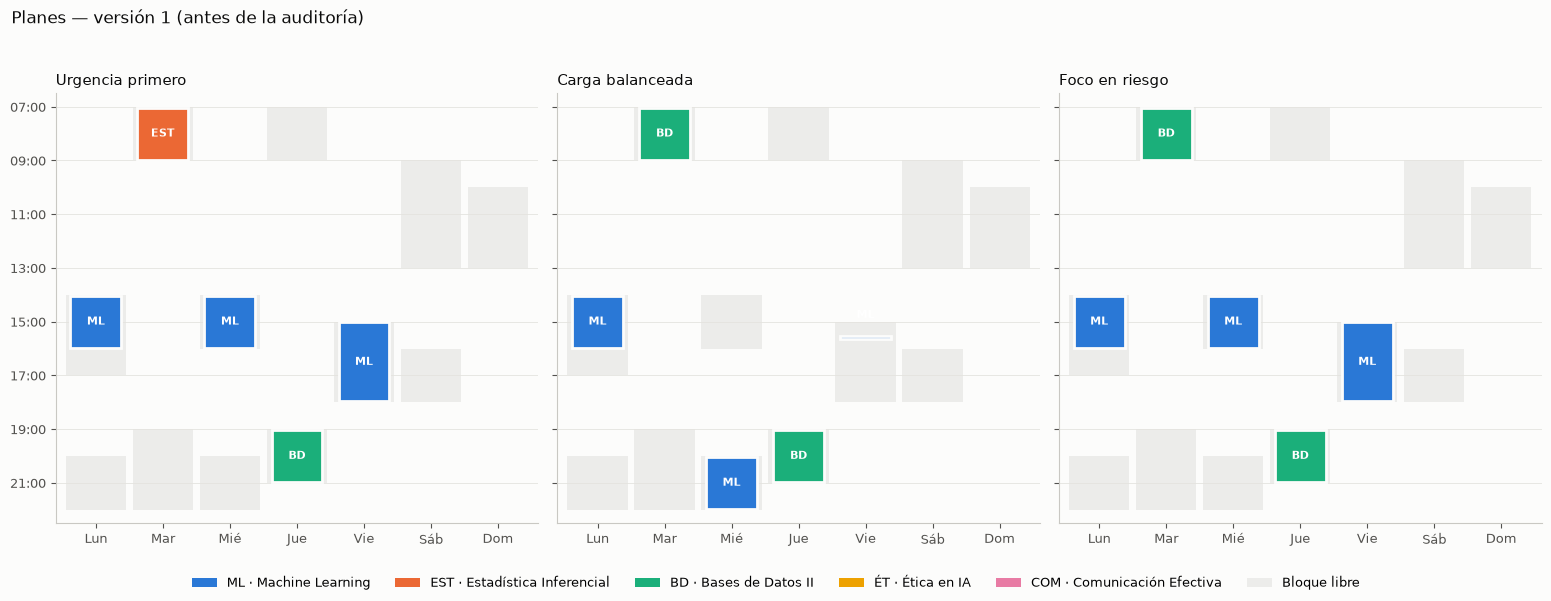

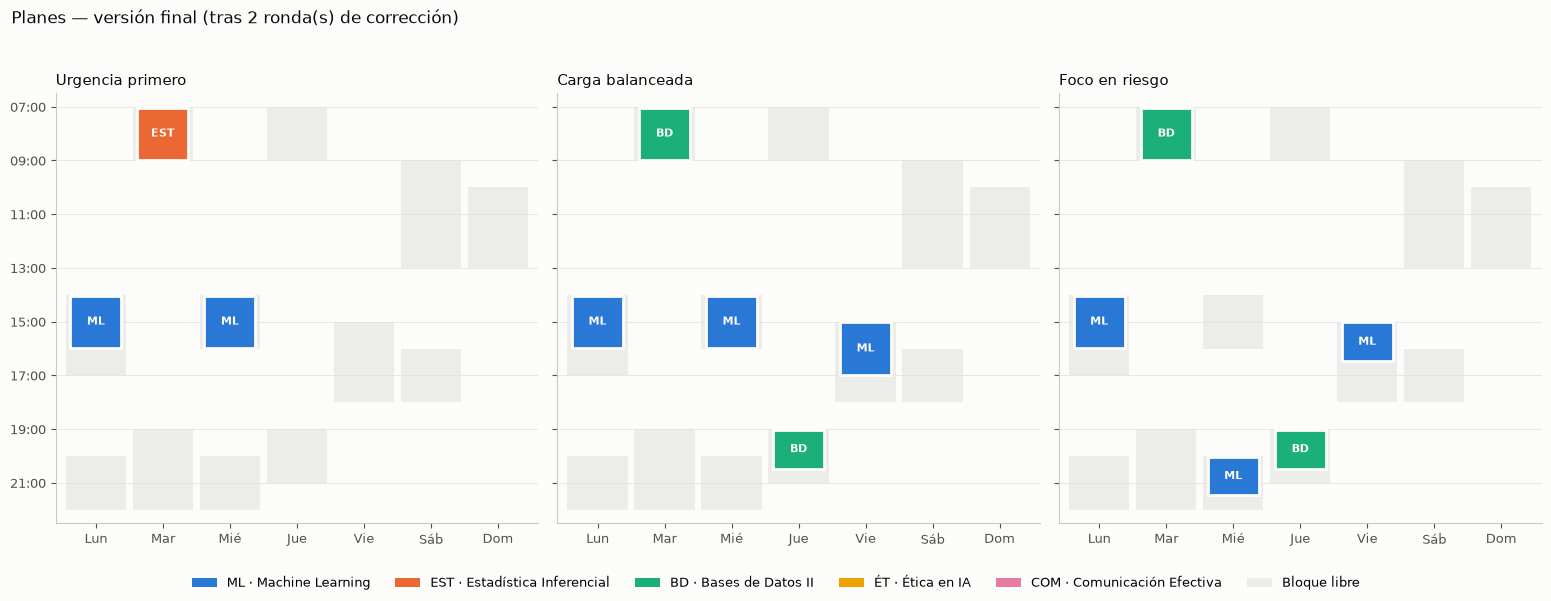

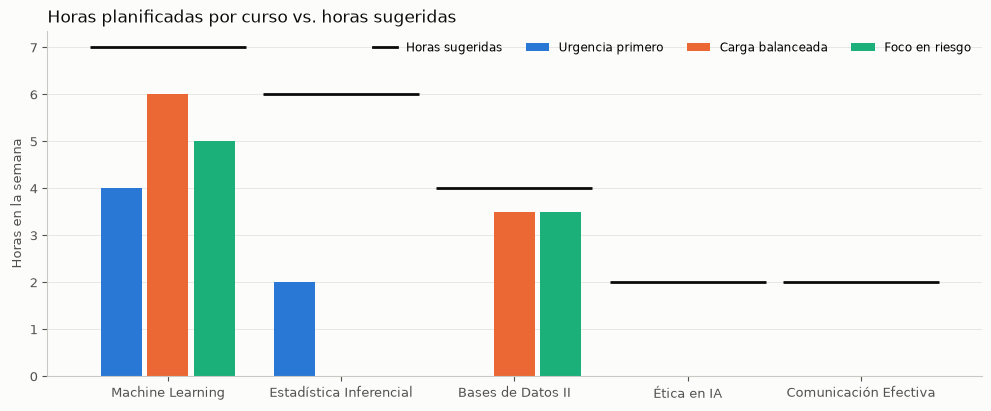

In [15]:
if len(HISTORIAL_PLANES) > 1:
    graficar_calendario(HISTORIAL_PLANES[0], ESTUDIANTE, "Planes — versión 1 (antes de la auditoría)",
                        "salidas/calendario_v1.png")
graficar_calendario(planes, ESTUDIANTE, f"Planes — versión final (tras {RONDAS_REALIZADAS} ronda(s) de corrección)",
                    "salidas/calendario_final.png")
graficar_horas(auditorias, ESTUDIANTE, "salidas/horas_por_curso.png")

### Paso 4 · Agente Evaluador de carga

In [16]:
evaluacion = ejecutar_paso("4. Evaluación", tarea_evaluacion, {
    "analisis": analisis,
    "planes": planes.model_dump_json(indent=1),
    "reporte": reporte,
    "informe_auditor": informe_auditor,
}, modelo=EvaluacionComparativa)
guardar("4_evaluacion.json", evaluacion)

for e in evaluacion.evaluaciones:
    display(Markdown(f"#### {e.plan}\n**Ventajas**\n" + "\n".join(f"- {v}" for v in e.ventajas)
                     + "\n\n**Desventajas**\n" + "\n".join(f"- {d}" for d in e.desventajas)))
display(Markdown(f"**Comentario general del evaluador:** {evaluacion.comentario_general}"))

# 4b · Puntaje ponderado calculado en Python (no por el LLM)
tabla_puntajes = puntaje_ponderado(evaluacion, auditorias)
guardar("4b_puntajes.csv", tabla_puntajes.to_csv())
display(Markdown("#### Matriz de evaluación y puntaje ponderado (pesos: " +
                 ", ".join(f"{c} {w:.0%}" for c, w in CRITERIOS.items()) + ")"))
display(tabla_puntajes)

▶ 4. Evaluación [Evaluador de carga académica] intento 1 ... 

✓ 52 s


#### Urgencia primero
**Ventajas**
- Prioriza las evaluaciones más cercanas, asegurando que Machine Learning y Estadística Inferencial cumplan con sus fechas límite.
- Mantiene un enfoque claro y directo para los cursos críticos.

**Desventajas**
- No dedica suficientes horas a todos los cursos, especialmente Bases de Datos II, Ética en IA y Comunicación Efectiva.
- Violaciones duras con estudio posterior a la evaluación y poca dedicación a Estadística Inferencial.

#### Carga balanceada
**Ventajas**
- Equilibra la carga de estudio durante toda la semana, garantizando que todos los cursos reciban atención.
- Respeto a las fechas límite más cercanas.

**Desventajas**
- Violaciones duras con estudio posterior a la evaluación y poca dedicación a Estadística Inferencial.
- No dedica suficientes horas a Machine Learning, Ética en IA y Comunicación Efectiva.

#### Foco en riesgo
**Ventajas**
- Enfatiza Machine Learning, el curso con mayor riesgo de desaprobar.
- Mantiene un enfoque claro y directo para los cursos críticos.

**Desventajas**
- Violaciones duras con estudio posterior a la evaluación y poca dedicación a Estadística Inferencial.
- No dedica suficientes horas a todos los cursos, especialmente Ética en IA y Comunicación Efectiva.

**Comentario general del evaluador:** Todos los planes presentan problemas similares: no cumplen con las horas mínimas recomendadas para varios cursos, tienen violaciones duras y no respetan preferencias. El equilibrio entre prioridad académica y factibilidad es un desafío en todos ellos.

#### Matriz de evaluación y puntaje ponderado (pesos: prioridad_academica 30%, factibilidad 25%, balance_carga 20%, bienestar 15%, preferencias 10%)

,prioridad_academica,factibilidad,balance_carga,bienestar,preferencias,puntaje_ponderado,violaciones_duras
plan,,,,,,,
Carga balanceada,3,2,4,3,1,2.75,2
Foco en riesgo,3,2,4,3,1,2.75,2
Urgencia primero,3,2,1,2,4,2.30,2


### Paso 5 · Agente Decisor (asesor académico)

In [17]:
decision = ejecutar_paso("5. Decisión", tarea_decision, {
    "analisis": analisis,
    "planes": planes.model_dump_json(indent=1),
    "informe_auditor": informe_auditor,
    "evaluacion": evaluacion.model_dump_json(indent=1),
    "puntajes": tabla_puntajes.to_string(),
})
guardar("5_decision.md", decision)
DURACION_TOTAL = time.time() - INICIO
display(Markdown(decision))

▶ 5. Decisión [Asesor académico (decisor final)] intento 1 ... 

✓ 56 s


PLAN SELECCIONADO: Carga balanceada

## Por qué se seleccionó
El plan "Carga balanceada" fue seleccionado porque equilibra la carga de estudio durante toda la semana, garantizando que todos los cursos reciban atención y respetando las fechas límite más cercanas. Aunque presenta algunas violaciones duras, este plan ofrece un mejor equilibrio entre prioridad académica y factibilidad en comparación con los otros planes.

## Criterios que más pesaron
1. **Equilibrio de la carga**: El plan "Carga balanceada" distribuye las horas de estudio de manera equitativa durante toda la semana, lo cual es crucial para mantener el rendimiento académico a largo plazo.
2. **Respeto a las fechas límite**: Aunque no cumple con todas las fechas límite, este plan mantiene un enfoque claro y directo para los cursos críticos, asegurando que Machine Learning y Estadística Inferencial cumplan con sus fechas más cercanas.

## Riesgos que permanecen
1. **Violaciones duras**: El plan tiene una violación duradera con el estudio posterior a la evaluación (Bases de Datos II) y no dedica suficientes horas al curso Estadística Inferencial.
2. **Distribución imbalanceda de las horas**: Aunque se intenta equilibrar, Machine Learning, Ética en IA y Comunicación Efectiva reciben menos horas que lo recomendado.

## Recomendaciones para el estudiante
1. **Ajuste del horario**: Mover la sesión del Jueves 19:00 - 20:30 (Bases de Datos II) a un día anterior.
2. **Asignación adicional de tiempo**: Añadir una nueva sesión para Estadística Inferencial en el bloque libre de Lunes 14:00 - 16:00 o Martes 07:00 - 09:00.

## Qué debe revisar una persona antes de aplicar el plan
1. **Horario ajustado**: Verificar que las sesiones se hayan movido correctamente y que no haya conflictos con otras actividades.
2. **Distribución de horas**: Asegurarse de que Machine Learning, Ética en IA y Comunicación Efectiva reciban al menos el 70% de sus horas sugeridas.

## Horario final (tabla con día, horario, curso y actividad)
| Día     | Horario    | Curso               | Actividad                          |
|---------|------------|---------------------|-----------------------------------|
| Lunes   | 14:00 - 16:00 | Machine Learning    | Estudio para examen parcial        |
| Martes  | 07:00 - 09:00 | Bases de Datos II   | Estudio para laboratorio calificado|
| Miércoles| 14:00 - 16:00 | Machine Learning    | Estudio para examen parcial        |
| Jueves  | 19:00 - 20:30 | Bases de Datos II   | Estudio para laboratorio calificado|
| Viernes | 15:00 - 17:00 | Machine Learning    | Estudio para examen parcial        |
| Sábado  | 09:00 - 13:00, 16:00 - 18:00 | No asignado         | Descanso y tiempo libre            |
| Domingo | 10:00 - 13:00 | No asignado         | Descanso y tiempo libre            |

Este horario final asegura un equilibrio entre la carga de estudio, las fechas límite más cercanas y el bienestar del estudiante.

### Traza de ejecución (evidencia)

Cada fila es una llamada real a un agente. Todas las salidas quedaron guardadas en la carpeta `salidas/`.

In [18]:
df_traza = pd.DataFrame(TRAZA)
display(df_traza)
print(f"Proveedor: {PROVEEDOR} | Modelo: {MODELO_OLLAMA if PROVEEDOR == 'ollama' else MODELO_GROQ}")
print(f"Llamadas a agentes: {len(df_traza)} | Rondas de corrección: {RONDAS_REALIZADAS} | "
      f"Tiempo total: {DURACION_TOTAL / 60:.1f} min")
print("Archivos generados:", sorted(p.name for p in SALIDAS.iterdir()))
df_traza.to_csv(SALIDAS / "traza_ejecucion.csv", index=False)

,paso,agente,intento,segundos,tokens_prompt,tokens_respuesta
0,1. Análisis,Analista académico del estudiante,1,37.2,1573,1058
1,2. Planificación,Diseñador de planes de estudio,1,54.7,3413,1023
2,3. Auditoría,Auditor de factibilidad y restricciones,1,59.6,2841,1165
3,2. Planificación,Diseñador de planes de estudio,1,97.3,9963,1946
4,3. Auditoría,Auditor de factibilidad y restricciones,1,71.4,5446,2260
5,2. Planificación,Diseñador de planes de estudio,1,86.5,16245,2869
6,3. Auditoría,Auditor de factibilidad y restricciones,1,59.3,8050,3330
7,4. Evaluación,Evaluador de carga académica,1,51.8,5196,596
8,5. Decisión,Asesor académico (decisor final),1,56.1,4230,847


Proveedor: ollama | Modelo: qwen2.5-planifica
Llamadas a agentes: 9 | Rondas de corrección: 2 | Tiempo total: 9.6 min
Archivos generados: ['1_analisis.md', '2_planes_v1.json', '2_planes_v2.json', '2_planes_v3.json', '3_auditoria_ronda0.md', '3_auditoria_ronda1.md', '3_auditoria_ronda2.md', '4_evaluacion.json', '4b_puntajes.csv', '5_decision.md', 'calendario_final.png', 'calendario_v1.png', 'horas_por_curso.png']


## 6.7 Decisión final

Antes de presentar la decisión, comprobamos con código que sea **consistente** con la evidencia: ¿el plan elegido existe, no tiene violaciones duras y coincide con el mejor puntaje ponderado?

,resultado,detalle
verificación,,
El decisor indicó un plan existente,True,Carga balanceada
El plan elegido no tiene violaciones duras,False,2
Coincide con el mayor puntaje ponderado,True,mejor puntaje: Carga balanceada


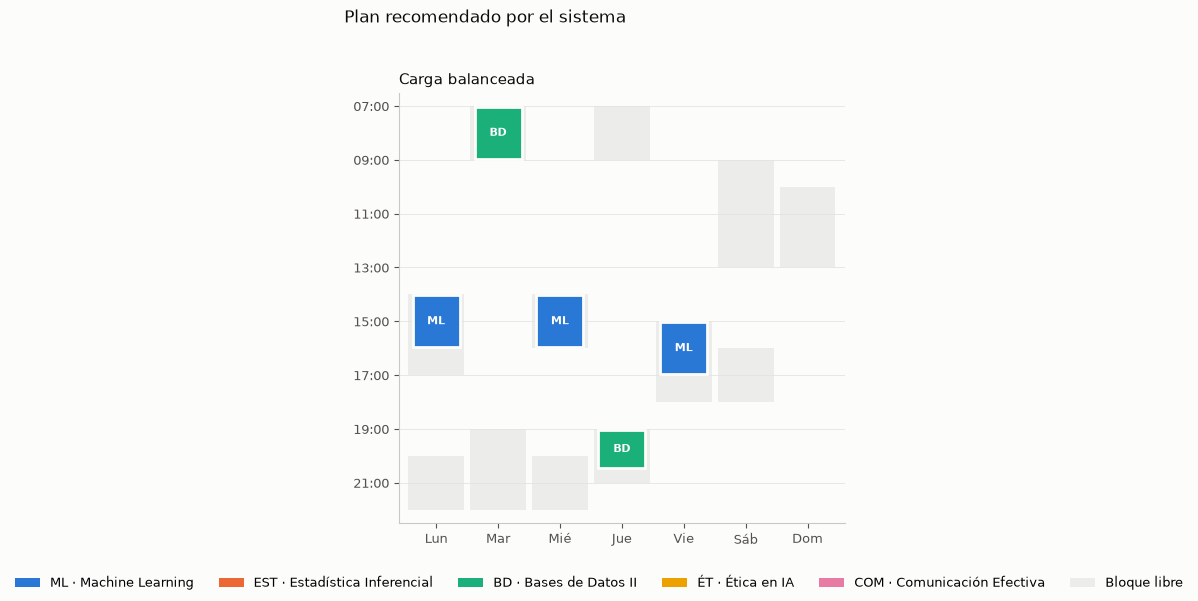

,dia,inicio,fin,curso,actividad
0,Lunes,14:00,16:00,Machine Learning,Estudio para examen parcial
1,Martes,07:00,09:00,Bases de Datos II,Estudio para laboratorio calificado
2,Miércoles,14:00,16:00,Machine Learning,Estudio para examen parcial
3,Jueves,19:00,20:30,Bases de Datos II,Estudio para laboratorio calificado
4,Viernes,15:00,17:00,Machine Learning,Estudio para examen parcial


,horas,sugeridas
Machine Learning,6.0,7
Estadística Inferencial,0.0,6
Bases de Datos II,3.5,4
Ética en IA,0.0,2
Comunicación Efectiva,0.0,2


In [19]:
m = re.search(r"PLAN SELECCIONADO:\s*\**\s*(.+)", decision)
elegido_texto = m.group(1).strip(" *`\"'") if m else ""
nombres = [p.nombre for p in planes.planes]
# Empate tolerante entre el texto del decisor y los nombres de los planes
elegido = next((n for n in nombres if _sin_tildes(n) in _sin_tildes(elegido_texto) or _sin_tildes(elegido_texto) in _sin_tildes(n)), None)
plan_final = next((p for p in planes.planes if p.nombre == elegido), None)
auditoria_final = next((a for a in auditorias if a["plan"] == elegido), None)
mejor_puntaje = tabla_puntajes.index[0]

chequeo = pd.DataFrame([
    {"verificación": "El decisor indicó un plan existente", "resultado": elegido is not None, "detalle": elegido_texto},
    {"verificación": "El plan elegido no tiene violaciones duras",
     "resultado": bool(auditoria_final) and not auditoria_final["violaciones_duras"],
     "detalle": len(auditoria_final["violaciones_duras"]) if auditoria_final else "—"},
    {"verificación": "Coincide con el mayor puntaje ponderado", "resultado": elegido == mejor_puntaje,
     "detalle": f"mejor puntaje: {mejor_puntaje}"},
]).set_index("verificación")
display(chequeo)

if plan_final:
    graficar_calendario(PlanesSemanales(planes=[plan_final]), ESTUDIANTE, "Plan recomendado por el sistema",
                        "salidas/plan_recomendado.png")
    df_final = pd.DataFrame([s.model_dump() for s in plan_final.sesiones])
    df_final["orden"] = df_final.dia.map(DIAS.index)
    display(df_final.sort_values(["orden", "inicio"]).drop(columns="orden").reset_index(drop=True))
    display(pd.Series(auditoria_final["horas_por_curso"], name="horas").to_frame()
            .assign(sugeridas=[c["horas_sugeridas"] for c in ESTUDIANTE["cursos"]]))

### Análisis de la decisión

*(Esta sección se completa tras ejecutar el notebook; ver la versión entregada.)*

## 6.8 Evaluación crítica

### Experimento: ¿qué pasa si los datos son incompletos o incorrectos?

Para responder con evidencia y no solo con opinión, corrompemos el perfil a propósito:
1. **Dato faltante:** eliminamos la disponibilidad del sábado y la nota actual de Machine Learning.
2. **Dato incorrecto:** las horas sugeridas de Estadística pasan de 6 a 60 (error de tipeo).
3. **Dato inconsistente:** el control de Ética figura el martes, pero su fecha límite dice domingo.

Luego (a) pasamos el perfil corrupto por el **Analista** para ver si detecta los problemas y (b) auditamos el **plan recomendado** con el verificador usando los datos corruptos.

In [20]:
import copy
CORRUPTO = copy.deepcopy(ESTUDIANTE)
CORRUPTO["disponibilidad"]["Sábado"] = []                     # el estudiante "olvidó" llenar el sábado
CORRUPTO["cursos"][0]["nota_actual"] = None                    # nota de ML faltante
CORRUPTO["cursos"][1]["horas_sugeridas"] = 60                  # error de tipeo (6 -> 60)
CORRUPTO["cursos"][3]["fecha_limite"] = {"dia": "Domingo", "hora": "23:59"}  # inconsistente con "martes"

analisis_corrupto = paso_analisis(CORRUPTO)
guardar("6_analisis_datos_corruptos.md", analisis_corrupto)
display(Markdown(analisis_corrupto))

▶ 1. Análisis [Analista académico del estudiante] intento 1 ... 

✓ 52 s


```markdown
# Análisis del perfil académico de Andrea

## 1. Situación general
- **Carrera**: Ciencia de Datos e IA (5º ciclo)
- **Semana**: Lunes 12 al domingo 18 de octubre de 2026 (semana 9)
- **Horas sugeridas totales por curso**:
  - Machine Learning: 7
  - Estadística Inferencial: 60
  - Bases de Datos II: 4
  - Ética en IA: 2
  - Comunicación Efectiva: 2

- **Horas libres totales**: 31 horas (5 por día * 6 días = 30 + 1 hora libre el sábado)

## 2. Cursos ordenados por prioridad calculada y nivel de riesgo
| Curso                | Prioridad | Nivel de Riesgo | Horas Sugeridas |
|----------------------|-----------|-----------------|----------------|
| Estadística Inferencial | Alta     | Alto            | 60             |
| Machine Learning      | Alta     | Alto            | 7              |
| Bases de Datos II     | Media    | Medio           | 4              |
| Ética en IA          | Media    | Bajo            | 2              |
| Comunicación Efectiva | Baja     | Bajo            | 2              |

- **Riesgo alto**: Estadística Inferencial y Machine Learning
- **Riesgo medio**: Bases de Datos II, Ética en IA
- **Riesgo bajo**: Comunicación Efectiva

## 3. Disponibilidad real
- **Lunes**: 2 horas (14:00 - 17:00), 2 horas (20:00 - 22:00)
- **Martes**: 2 horas (07:00 - 09:00), 3 horas (19:00 - 22:00)
- **Miércoles**: 2 horas (14:00 - 16:00), 2 horas (20:00 - 22:00)
- **Jueves**: 2 horas (07:00 - 09:00), 2 horas (19:00 - 21:00)
- **Viernes**: 3 horas (15:00 - 18:00)
- **Sábado**: Sin disponibilidad
- **Domingo**: 3 horas (10:00 - 13:00)

## 4. Restricciones duras y preferencias
- **Restricciones**:
  1. Solo puede estudiar dentro de los bloques de disponibilidad indicados.
  2. Máximo 5 horas de estudio por día.
  3. No estudiar después de las 22:00.
  4. El estudio de un curso debe terminar antes de su evaluación (fecha_limite).
  5. Los cursos con prioridad alta deben recibir al menos el 70% de sus horas sugeridas.

- **Preferencias**:
  1. Rinde mejor en la mañana: preferiría estudiar los cursos difíciles (dificultad 4-5) antes de las 13:00.
  2. Sesiones de máximo 2 horas seguidas del mismo curso.
  3. Quiere al menos un bloque libre el fin de semana para descansar.

## 5. Fechas límite que condicionan el orden del estudio
- **Estadística Inferencial**: Viernes 16/10 a las 23:59
- **Machine Learning**: Examen parcial lunes 19/10 (semana siguiente)
- **Bases de Datos II**: Laboratorio calificado jueves 15/10 a las 10:00
- **Ética en IA**: Control de lectura domingo 13/10 a las 23:59

## 6. Datos faltantes, inconsistentes o supuestos que estás asumiendo
- **Datos faltantes**:
  - Nota actual para Machine Learning.
  - Fecha_limite para Comunicación Efectiva.

- **Inconsistencias**:
  - La nota actual de Estadística Inferencial es 13, pero la evaluación se entrega el viernes 16/10. Es probable que esta sea una nota parcial o preliminar.
  
- **Supuestos**:
  - Se asume que las horas sugeridas son necesarias para alcanzar un buen rendimiento en cada curso.
  - Se supone que la disponibilidad indicada es real y no se pueden realizar actividades fuera de estos horarios.
```

In [21]:
if plan_final:
    a_ok = auditar_plan(plan_final, ESTUDIANTE)
    a_mal = auditar_plan(plan_final, CORRUPTO)
    display(pd.DataFrame({
        "datos correctos": [len(a_ok["violaciones_duras"]), len(a_ok["observaciones"]), a_ok["cobertura"]["Estadística Inferencial"]],
        "datos corruptos": [len(a_mal["violaciones_duras"]), len(a_mal["observaciones"]), a_mal["cobertura"]["Estadística Inferencial"]],
    }, index=["violaciones duras", "observaciones", "cobertura Estadística"]))
    display(Markdown("**Violaciones que aparecen con los datos corruptos:**\n" +
                     "\n".join(f"- {v}" for v in a_mal["violaciones_duras"] if v not in a_ok["violaciones_duras"])))

,datos correctos,datos corruptos
violaciones duras,2.0,2.0
observaciones,3.0,3.0
cobertura Estadística,0.0,0.0


**Violaciones que aparecen con los datos corruptos:**
- Curso crítico con poca dedicación: Estadística Inferencial 0.0 h de 60 h sugeridas

### Respuestas a las preguntas de evaluación crítica

*(Esta sección se completa tras ejecutar el notebook; ver la versión entregada.)*

## Conclusiones

*(Esta sección se completa tras ejecutar el notebook; ver la versión entregada.)*